In [1]:
# ============================================================
# CELL 1 — INSTALL REQUIRED PACKAGES
# RAJSHAHI DIVISION URBAN CENTER MAPPING
# ============================================================

!pip -q install geemap geopandas pyogrio osmnx rasterio rioxarray \
    shapely folium mapclassify overturemaps duckdb

print("✅ Packages installed successfully.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 104.7/104.7 kB 6.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.4/72.4 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 39.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 24.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 59.6 MB/s eta 0:00:00
✅ Packages installed successfully.


In [2]:
# ============================================================
# CELL 2 — UPLOAD BANGLADESH ADMIN-1 SHAPEFILE
# RAJSHAHI DIVISION WORKFLOW
# ============================================================

from google.colab import files
import os
import glob
import shutil

UPLOAD_DIR = "/content/admin1"
os.makedirs(UPLOAD_DIR, exist_ok=True)

print("Select ALL shapefile components together:")
print("Required: .shp  .shx  .dbf  .prj")
print("Optional: .cpg")

uploaded = files.upload()

# Move uploaded files into one folder
for filename in uploaded.keys():

    src = f"/content/{filename}"

    dst = os.path.join(
        UPLOAD_DIR,
        os.path.basename(filename)
    )

    if os.path.exists(src):
        shutil.move(src, dst)

print("\nUploaded files:")

for f in os.listdir(UPLOAD_DIR):
    print(" -", f)

# Find shapefile
shp_files = glob.glob(
    os.path.join(
        UPLOAD_DIR,
        "*.shp"
    )
)

if len(shp_files) == 0:

    raise FileNotFoundError(
        "❌ .shp file not found. "
        "Upload .shp, .shx, .dbf and .prj together."
    )

ADMIN1_SHP = shp_files[0]

print("\n✅ Admin-1 shapefile ready:")
print(ADMIN1_SHP)

Select ALL shapefile components together:
Required: .shp  .shx  .dbf  .prj
Optional: .cpg


Saving bgd_admin1.cpg to bgd_admin1.cpg
Saving bgd_admin1.dbf to bgd_admin1.dbf
Saving bgd_admin1.prj to bgd_admin1.prj
Saving bgd_admin1.shp to bgd_admin1.shp
Saving bgd_admin1.shx to bgd_admin1.shx

Uploaded files:
 - bgd_admin1.shp
 - bgd_admin1.prj
 - bgd_admin1.dbf
 - bgd_admin1.cpg
 - bgd_admin1.shx

✅ Admin-1 shapefile ready:
/content/admin1/bgd_admin1.shp


In [3]:
# ============================================================
# CELL 3 — READ ADMIN-1 + VERIFY RAJSHAHI DIVISION
# ============================================================

import geopandas as gpd

print("=" * 70)
print("BANGLADESH ADMIN-1 SHAPEFILE CHECK")
print("=" * 70)

# Read shapefile
admin1 = gpd.read_file(ADMIN1_SHP)

print("\nTotal features:", len(admin1))
print("CRS:", admin1.crs)

print("\nColumns:")
print(admin1.columns.tolist())

# ------------------------------------------------------------
# Show division names
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("DIVISIONS")
print("=" * 70)

print(
    admin1[
        [
            "adm1_name",
            "adm1_pcode",
            "area_sqkm",
            "center_lat",
            "center_lon"
        ]
    ].to_string(index=False)
)

# ------------------------------------------------------------
# Find Rajshahi
# ------------------------------------------------------------

rajshahi_check = admin1[
    admin1["adm1_name"]
    .astype(str)
    .str.strip()
    .str.lower()
    .eq("rajshahi")
].copy()

print("\n" + "=" * 70)
print("RAJSHAHI CHECK")
print("=" * 70)

if len(rajshahi_check) == 0:

    print("❌ Rajshahi Division not found.")

else:

    print("✅ Rajshahi Division found.")

    row = rajshahi_check.iloc[0]

    print("\nName       :", row["adm1_name"])
    print("PCode      :", row["adm1_pcode"])
    print("Area sq.km :", row["area_sqkm"])
    print("Center Lat :", row["center_lat"])
    print("Center Lon :", row["center_lon"])

    print("\nBounding box:")
    print(rajshahi_check.total_bounds)

BANGLADESH ADMIN-1 SHAPEFILE CHECK

Total features: 8
CRS: EPSG:4326

Columns:
['adm1_name', 'adm1_name1', 'adm1_name2', 'adm1_name3', 'adm1_pcode', 'adm0_name', 'adm0_name1', 'adm0_name2', 'adm0_name3', 'adm0_pcode', 'valid_on', 'valid_to', 'area_sqkm', 'version', 'lang', 'lang1', 'lang2', 'lang3', 'adm1_ref_n', 'center_lat', 'center_lon', 'geometry']

DIVISIONS
 adm1_name adm1_pcode    area_sqkm  center_lat  center_lon
  Barishal       BD10 12693.470554   22.392843   90.406395
Chattogram       BD20 32833.077336   22.701308   91.705861
     Dhaka       BD30 20426.531733   23.839021   90.242159
    Khulna       BD40 22584.724276   22.837718   89.304779
Mymensingh       BD45 10512.774130   24.847830   90.381745
  Rajshahi       BD50 18255.461893   24.589338   89.046363
   Rangpur       BD55 16282.752692   25.780421   89.054095
    Sylhet       BD60 12373.311774   24.715289   91.664713

RAJSHAHI CHECK
✅ Rajshahi Division found.

Name       : Rajshahi
PCode      : BD50
Area sq.km : 18255.

EXTRACTING RAJSHAHI DIVISION

✅ Rajshahi Division extracted.

Name       : Rajshahi
PCode      : BD50
Area attr. : 18255.46 sq.km
CRS        : EPSG:4326

Bounding Box:
West  : 88.00816912400006
South : 23.806272905000185
East  : 89.82626140100007
North : 25.27684120300006

Center coordinates:
Latitude  : 24.58933841
Longitude : 89.04636294

✅ Rajshahi boundary saved:
/content/rajshahi_boundary/Rajshahi_Division.shp

✅ Rajshahi Division extraction complete.


/usr/local/lib/python3.13/dist-packages/pyogrio/raw.py:733: RuntimeWarning: Field valid_on created as String field, though DateTime requested.
  ogr_write(
/usr/local/lib/python3.13/dist-packages/pyogrio/raw.py:733: RuntimeWarning: Field valid_to created as String field, though DateTime requested.
  ogr_write(


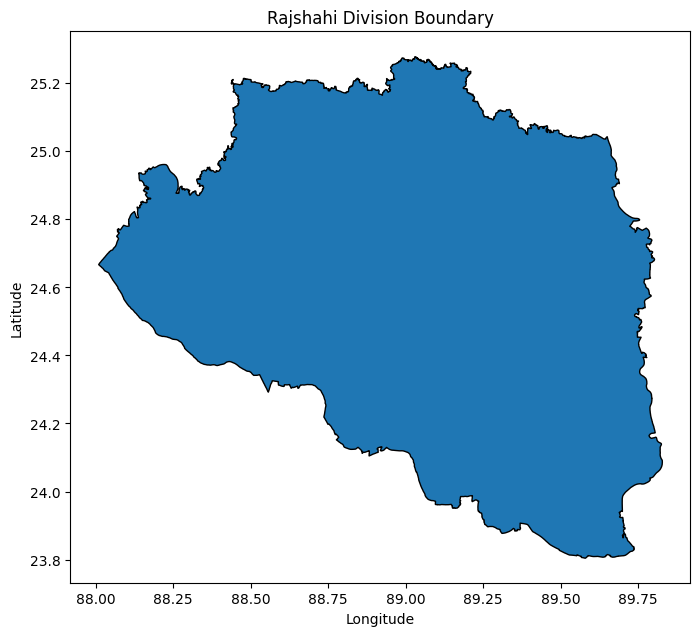

In [4]:
# ============================================================
# CELL 4 — EXTRACT RAJSHAHI DIVISION BOUNDARY
# ============================================================

import geopandas as gpd
import os

print("=" * 70)
print("EXTRACTING RAJSHAHI DIVISION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Extract Rajshahi
# ------------------------------------------------------------

rajshahi = admin1[
    admin1["adm1_name"]
    .astype(str)
    .str.strip()
    .str.lower()
    .eq("rajshahi")
].copy()

if len(rajshahi) == 0:
    raise ValueError("❌ Rajshahi Division not found.")

print("\n✅ Rajshahi Division extracted.")

# ------------------------------------------------------------
# 2. Basic information
# ------------------------------------------------------------

row = rajshahi.iloc[0]

print("\nName       :", row["adm1_name"])
print("PCode      :", row["adm1_pcode"])
print("Area attr. :", round(float(row["area_sqkm"]), 2), "sq.km")
print("CRS        :", rajshahi.crs)

xmin, ymin, xmax, ymax = rajshahi.total_bounds

print("\nBounding Box:")
print("West  :", xmin)
print("South :", ymin)
print("East  :", xmax)
print("North :", ymax)

print("\nCenter coordinates:")
print("Latitude  :", row["center_lat"])
print("Longitude :", row["center_lon"])

# ------------------------------------------------------------
# 3. Save boundary
# ------------------------------------------------------------

RAJSHAHI_DIR = "/content/rajshahi_boundary"

os.makedirs(
    RAJSHAHI_DIR,
    exist_ok=True
)

RAJSHAHI_SHP = os.path.join(
    RAJSHAHI_DIR,
    "Rajshahi_Division.shp"
)

rajshahi.to_file(
    RAJSHAHI_SHP
)

print("\n✅ Rajshahi boundary saved:")
print(RAJSHAHI_SHP)

# ------------------------------------------------------------
# 4. Quick map
# ------------------------------------------------------------

ax = rajshahi.plot(
    figsize=(8, 8),
    edgecolor="black"
)

ax.set_title(
    "Rajshahi Division Boundary"
)

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

print(
    "\n✅ Rajshahi Division extraction complete."
)

In [5]:
# ============================================================
# CELL 5 — GOOGLE EARTH ENGINE SETUP
# RAJSHAHI DIVISION ROI + AREA CHECK
# ============================================================

import ee
import geopandas as gpd

print("=" * 70)
print("GOOGLE EARTH ENGINE SETUP — RAJSHAHI")
print("=" * 70)

# ------------------------------------------------------------
# 1. Authenticate Earth Engine
# ------------------------------------------------------------

try:
    ee.Initialize(
        project="solid-garden-458417-t4"
    )

    print("\n✅ Earth Engine already initialized.")

except Exception:

    print("\nEarth Engine authentication required...")

    ee.Authenticate()

    ee.Initialize(
        project="solid-garden-458417-t4"
    )

    print("\n✅ Earth Engine authenticated and initialized.")

# ------------------------------------------------------------
# 2. Ensure WGS84
# ------------------------------------------------------------

rajshahi_wgs84 = (
    rajshahi
    .to_crs("EPSG:4326")
)

# ------------------------------------------------------------
# 3. Convert boundary to Earth Engine geometry
# ------------------------------------------------------------

rajshahi_geom = (
    rajshahi_wgs84
    .geometry
    .union_all()
)

roi = ee.Geometry(
    rajshahi_geom.__geo_interface__
)

print("\n✅ Rajshahi ROI converted to Earth Engine geometry.")

# ------------------------------------------------------------
# 4. Area comparison
# ------------------------------------------------------------

shapefile_area = float(
    rajshahi.iloc[0]["area_sqkm"]
)

ee_area_km2 = (
    roi.area(maxError=1)
    .divide(1e6)
    .getInfo()
)

difference = abs(
    ee_area_km2 - shapefile_area
)

print("\n" + "=" * 70)
print("AREA CHECK")
print("=" * 70)

print(
    "Shapefile area :",
    round(shapefile_area, 2),
    "km²"
)

print(
    "Earth Engine   :",
    round(ee_area_km2, 2),
    "km²"
)

print(
    "Difference     :",
    round(difference, 2),
    "km²"
)

# ------------------------------------------------------------
# 5. Bounding box
# ------------------------------------------------------------

xmin, ymin, xmax, ymax = (
    rajshahi_wgs84.total_bounds
)

print("\nBounding Box:")
print("West  :", xmin)
print("South :", ymin)
print("East  :", xmax)
print("North :", ymax)

# ------------------------------------------------------------
# 6. SRTM test
# ------------------------------------------------------------

srtm = (
    ee.Image("USGS/SRTMGL1_003")
    .select("elevation")
    .clip(roi)
)

srtm_test = (
    srtm.reduceRegion(
        reducer=ee.Reducer.minMax(),
        geometry=roi,
        scale=90,
        maxPixels=1e9,
        bestEffort=True
    )
    .getInfo()
)

print("\nSRTM connection test:")
print(
    "Elevation min:",
    srtm_test.get("elevation_min")
)
print(
    "Elevation max:",
    srtm_test.get("elevation_max")
)

print("\n✅ Rajshahi GEE ROI ready.")

GOOGLE EARTH ENGINE SETUP — RAJSHAHI

Earth Engine authentication required...


*** Earth Engine *** Share your feedback by taking our Annual Developer Satisfaction Survey: https://google.qualtrics.com/jfe/form/SV_9oS0DRcPvElRMNw?source=python



✅ Earth Engine authenticated and initialized.

✅ Rajshahi ROI converted to Earth Engine geometry.

AREA CHECK
Shapefile area : 18255.46 km²
Earth Engine   : 18294.94 km²
Difference     : 39.48 km²

Bounding Box:
West  : 88.00816912400006
South : 23.806272905000185
East  : 89.82626140100007
North : 25.27684120300006

SRTM connection test:
Elevation min: -21
Elevation max: 59

✅ Rajshahi GEE ROI ready.


In [6]:
# ============================================================
# CELL 6 — SENTINEL-2 COLLECTION CHECK
# RAJSHAHI DIVISION | JAN–MAR 2025
# ============================================================

import ee

print("=" * 70)
print("SENTINEL-2 COLLECTION CHECK — RAJSHAHI DIVISION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Date range
# ------------------------------------------------------------

START_DATE = "2025-01-01"
END_DATE   = "2025-04-01"   # exclusive

# ------------------------------------------------------------
# 2. Sentinel-2 Surface Reflectance Harmonized
# ------------------------------------------------------------

s2 = (
    ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
    .filterBounds(roi)
    .filterDate(START_DATE, END_DATE)
    .filter(
        ee.Filter.lte(
            "CLOUDY_PIXEL_PERCENTAGE",
            30
        )
    )
)

# ------------------------------------------------------------
# 3. Scene count
# ------------------------------------------------------------

scene_count = s2.size().getInfo()

print("\nDate range:")
print("Start :", START_DATE)
print("End   :", "2025-03-31")

print("\nCloud filter:")
print("CLOUDY_PIXEL_PERCENTAGE <= 30%")

print("\nTotal Sentinel-2 scenes :", scene_count)

# ------------------------------------------------------------
# 4. Unique acquisition dates
# ------------------------------------------------------------

date_list = (
    s2.aggregate_array("system:time_start")
    .map(
        lambda t: ee.Date(t).format("YYYY-MM-dd")
    )
    .distinct()
    .sort()
    .getInfo()
)

print(
    "Unique acquisition dates :",
    len(date_list)
)

print("\nFirst 10 dates:")
for d in date_list[:10]:
    print(" -", d)

print("\nLast 10 dates:")
for d in date_list[-10:]:
    print(" -", d)

# ------------------------------------------------------------
# 5. MGRS tiles
# ------------------------------------------------------------

tile_ids = (
    s2.aggregate_array("MGRS_TILE")
    .distinct()
    .sort()
    .getInfo()
)

print(
    "\nUnique MGRS tiles :",
    len(tile_ids)
)

print(tile_ids)

# ------------------------------------------------------------
# 6. First image check
# ------------------------------------------------------------

if scene_count > 0:

    first_img = ee.Image(
        s2.first()
    )

    first_date = ee.Date(
        first_img.get("system:time_start")
    ).format(
        "YYYY-MM-dd"
    ).getInfo()

    first_cloud = (
        first_img
        .get("CLOUDY_PIXEL_PERCENTAGE")
        .getInfo()
    )

    first_tile = (
        first_img
        .get("MGRS_TILE")
        .getInfo()
    )

    print("\nFirst image:")
    print("Date      :", first_date)
    print("MGRS tile :", first_tile)
    print(
        "Cloud (%) :",
        round(first_cloud, 2)
    )

else:

    raise ValueError(
        "❌ No Sentinel-2 scenes found."
    )

print(
    "\n✅ Sentinel-2 collection check complete."
)

SENTINEL-2 COLLECTION CHECK — RAJSHAHI DIVISION

Date range:
Start : 2025-01-01
End   : 2025-03-31

Cloud filter:
CLOUDY_PIXEL_PERCENTAGE <= 30%

Total Sentinel-2 scenes : 137
Unique acquisition dates : 32

First 10 dates:
 - 2025-01-03
 - 2025-01-05
 - 2025-01-10
 - 2025-01-13
 - 2025-01-15
 - 2025-01-18
 - 2025-01-20
 - 2025-01-25
 - 2025-01-28
 - 2025-02-02

Last 10 dates:
 - 2025-03-06
 - 2025-03-09
 - 2025-03-11
 - 2025-03-14
 - 2025-03-16
 - 2025-03-19
 - 2025-03-24
 - 2025-03-26
 - 2025-03-29
 - 2025-03-31

Unique MGRS tiles : 7
['45QXG', '45QYG', '45RWH', '45RXH', '45RXJ', '45RYH', '45RYJ']

First image:
Date      : 2025-01-03
MGRS tile : 45QXG
Cloud (%) : 0.03

✅ Sentinel-2 collection check complete.


In [7]:
# ============================================================
# CELL 7 — SENTINEL-2 CLOUD MASK + MEDIAN COMPOSITE
# RAJSHAHI DIVISION
# ============================================================

import ee

print("=" * 70)
print("SENTINEL-2 CLOUD MASK + COMPOSITE — RAJSHAHI")
print("=" * 70)

# ------------------------------------------------------------
# 1. Cloud masking function
# ------------------------------------------------------------

def mask_s2_clouds(img):

    scl = img.select("SCL")

    # Remove:
    # 3  = Cloud shadow
    # 8  = Cloud medium probability
    # 9  = Cloud high probability
    # 10 = Cirrus
    # 11 = Snow / ice

    mask = (
        scl.neq(3)
        .And(scl.neq(8))
        .And(scl.neq(9))
        .And(scl.neq(10))
        .And(scl.neq(11))
    )

    spectral = img.select(
        ["B2", "B3", "B4", "B8", "B11", "B12"]
    )

    return (
        spectral
        .updateMask(mask)
        .divide(10000)
        .copyProperties(
            img,
            ["system:time_start"]
        )
    )

# ------------------------------------------------------------
# 2. Apply cloud mask
# ------------------------------------------------------------

s2_clean = s2.map(
    mask_s2_clouds
)

print("\n✅ Cloud masking applied.")

# ------------------------------------------------------------
# 3. Median composite
# ------------------------------------------------------------

s2_composite = (
    s2_clean
    .median()
    .clip(roi)
)

print("✅ Median composite created.")

# ------------------------------------------------------------
# 4. Check bands
# ------------------------------------------------------------

bands = s2_composite.bandNames().getInfo()

print("\nComposite bands:")
print(bands)

print("\nBand meaning:")
print("B2  = Blue")
print("B3  = Green")
print("B4  = Red")
print("B8  = NIR")
print("B11 = SWIR1")
print("B12 = SWIR2")

print("\n✅ Sentinel-2 composite ready.")

SENTINEL-2 CLOUD MASK + COMPOSITE — RAJSHAHI

✅ Cloud masking applied.
✅ Median composite created.

Composite bands:
['B2', 'B3', 'B4', 'B8', 'B11', 'B12']

Band meaning:
B2  = Blue
B3  = Green
B4  = Red
B8  = NIR
B11 = SWIR1
B12 = SWIR2

✅ Sentinel-2 composite ready.


In [8]:
# ============================================================
# CELL 8 — SENTINEL-2 SPECTRAL INDICES
# RAJSHAHI DIVISION
# NDVI, NDBI, MNDWI, BSI
# ============================================================

import ee

print("=" * 70)
print("SENTINEL-2 INDEX CALCULATION — RAJSHAHI")
print("=" * 70)

# ------------------------------------------------------------
# 1. NDVI
# (NIR - Red) / (NIR + Red)
# ------------------------------------------------------------

ndvi = (
    s2_composite
    .normalizedDifference(["B8", "B4"])
    .rename("NDVI")
)

# ------------------------------------------------------------
# 2. NDBI
# (SWIR1 - NIR) / (SWIR1 + NIR)
# ------------------------------------------------------------

ndbi = (
    s2_composite
    .normalizedDifference(["B11", "B8"])
    .rename("NDBI")
)

# ------------------------------------------------------------
# 3. MNDWI
# (Green - SWIR1) / (Green + SWIR1)
# ------------------------------------------------------------

mndwi = (
    s2_composite
    .normalizedDifference(["B3", "B11"])
    .rename("MNDWI")
)

# ------------------------------------------------------------
# 4. BSI
# ((SWIR1 + Red) - (NIR + Blue))
# --------------------------------
# ((SWIR1 + Red) + (NIR + Blue))
# ------------------------------------------------------------

bsi = s2_composite.expression(
    """
    ((SWIR1 + RED) - (NIR + BLUE)) /
    ((SWIR1 + RED) + (NIR + BLUE))
    """,
    {
        "SWIR1": s2_composite.select("B11"),
        "RED":   s2_composite.select("B4"),
        "NIR":   s2_composite.select("B8"),
        "BLUE":  s2_composite.select("B2")
    }
).rename("BSI")

# ------------------------------------------------------------
# 5. Combine indices
# ------------------------------------------------------------

s2_indices = (
    ndvi
    .addBands(ndbi)
    .addBands(mndwi)
    .addBands(bsi)
    .clip(roi)
)

print("\n✅ NDVI calculated")
print("✅ NDBI calculated")
print("✅ MNDWI calculated")
print("✅ BSI calculated")

print("\nIndex bands:")
print(s2_indices.bandNames().getInfo())

# ------------------------------------------------------------
# 6. Percentile statistics
# ------------------------------------------------------------

index_stats = s2_indices.reduceRegion(
    reducer=ee.Reducer.percentile(
        [1, 5, 25, 50, 75, 95, 99]
    ),
    geometry=roi,
    scale=100,
    maxPixels=1e10,
    bestEffort=True,
    tileScale=4
).getInfo()

print("\n" + "=" * 70)
print("INDEX PERCENTILE STATISTICS")
print("=" * 70)

for key in sorted(index_stats.keys()):

    value = index_stats[key]

    if value is not None:
        print(f"{key:15s}: {value:.4f}")
    else:
        print(f"{key:15s}: None")

print("\n✅ Sentinel-2 indices ready.")

SENTINEL-2 INDEX CALCULATION — RAJSHAHI

✅ NDVI calculated
✅ NDBI calculated
✅ MNDWI calculated
✅ BSI calculated

Index bands:
['NDVI', 'NDBI', 'MNDWI', 'BSI']

INDEX PERCENTILE STATISTICS
BSI_p1         : -0.3770
BSI_p25        : -0.1582
BSI_p5         : -0.2598
BSI_p50        : -0.0996
BSI_p75        : -0.0410
BSI_p95        : 0.0918
BSI_p99        : 0.1425
MNDWI_p1       : -0.4880
MNDWI_p25      : -0.4023
MNDWI_p5       : -0.4569
MNDWI_p50      : -0.3555
MNDWI_p75      : -0.2930
MNDWI_p95      : -0.1133
MNDWI_p99      : 0.5508
NDBI_p1        : -0.4492
NDBI_p25       : -0.2460
NDBI_p5        : -0.3554
NDBI_p50       : -0.1758
NDBI_p75       : -0.1055
NDBI_p95       : 0.0585
NDBI_p99       : 0.1522
NDVI_p1        : -0.2773
NDVI_p25       : 0.4414
NDVI_p5        : 0.1212
NDVI_p50       : 0.5274
NDVI_p75       : 0.5976
NDVI_p95       : 0.7148
NDVI_p99       : 0.8085

✅ Sentinel-2 indices ready.


In [9]:
# ============================================================
# CELL 9 — BUILT-UP RAW SCORE
# RAJSHAHI DIVISION
# SAME METHOD AS DHAKA / KHULNA / CHATTOGRAM
# ============================================================

import ee

print("=" * 70)
print("BUILT-UP RAW SCORE — RAJSHAHI")
print("=" * 70)

# ------------------------------------------------------------
# 1. Normalize indices from [-1, +1] to [0, 1]
# ------------------------------------------------------------

ndbi_n = (
    ndbi.add(1)
    .divide(2)
    .clamp(0, 1)
)

bsi_n = (
    bsi.add(1)
    .divide(2)
    .clamp(0, 1)
)

ndvi_n = (
    ndvi.add(1)
    .divide(2)
    .clamp(0, 1)
)

mndwi_n = (
    mndwi.add(1)
    .divide(2)
    .clamp(0, 1)
)

# ------------------------------------------------------------
# 2. Inverse vegetation / water tendency
# ------------------------------------------------------------

inv_ndvi = (
    ee.Image(1)
    .subtract(ndvi_n)
)

inv_mndwi = (
    ee.Image(1)
    .subtract(mndwi_n)
)

# ------------------------------------------------------------
# 3. Weighted built-up raw score
# ------------------------------------------------------------

builtup_raw = (
    ndbi_n.multiply(0.40)
    .add(
        bsi_n.multiply(0.25)
    )
    .add(
        inv_ndvi.multiply(0.20)
    )
    .add(
        inv_mndwi.multiply(0.15)
    )
    .rename("Builtup_Raw")
)

# ------------------------------------------------------------
# 4. Water + dense vegetation masks
# ------------------------------------------------------------

water_mask = (
    mndwi.gt(0)
)

dense_veg_mask = (
    ndvi.gt(0.45)
)

valid_builtup_mask = (
    water_mask.Not()
    .And(
        dense_veg_mask.Not()
    )
)

builtup_raw_masked = (
    builtup_raw
    .updateMask(valid_builtup_mask)
    .clip(roi)
)

print("\n✅ Weighted built-up raw score created.")
print("✅ Water mask applied      : MNDWI > 0")
print("✅ Dense vegetation masked : NDVI > 0.45")

# ------------------------------------------------------------
# 5. Percentile statistics
# ------------------------------------------------------------

builtup_stats = (
    builtup_raw_masked
    .reduceRegion(
        reducer=ee.Reducer.percentile(
            [1, 5, 25, 50, 75, 90, 95, 99]
        ),
        geometry=roi,
        scale=100,
        maxPixels=1e10,
        bestEffort=True,
        tileScale=4
    )
    .getInfo()
)

print("\n" + "=" * 70)
print("BUILT-UP RAW SCORE PERCENTILES")
print("=" * 70)

for key in sorted(builtup_stats.keys()):

    val = builtup_stats[key]

    if val is not None:
        print(
            f"{key:20s}: "
            f"{val:.4f}"
        )
    else:
        print(
            f"{key:20s}: None"
        )

# ------------------------------------------------------------
# 6. Valid built-up search area
# ------------------------------------------------------------

mask_area = (
    ee.Image.pixelArea()
    .updateMask(valid_builtup_mask)
    .reduceRegion(
        reducer=ee.Reducer.sum(),
        geometry=roi,
        scale=100,
        maxPixels=1e10,
        bestEffort=True,
        tileScale=4
    )
    .get("area")
)

mask_area_km2 = (
    ee.Number(mask_area)
    .divide(1e6)
    .getInfo()
)

mask_percent = (
    mask_area_km2
    / ee_area_km2
    * 100
)

print("\n" + "=" * 70)
print("VALID BUILT-UP SEARCH AREA")
print("=" * 70)

print(
    "Valid non-water/non-dense-veg area :",
    round(mask_area_km2, 2),
    "sq.km"
)

print(
    "Share of Rajshahi ROI              :",
    round(mask_percent, 2),
    "%"
)

print("\n✅ Built-up raw score ready.")

BUILT-UP RAW SCORE — RAJSHAHI

✅ Weighted built-up raw score created.
✅ Water mask applied      : MNDWI > 0
✅ Dense vegetation masked : NDVI > 0.45

BUILT-UP RAW SCORE PERCENTILES
Builtup_Raw_p1      : 0.3799
Builtup_Raw_p25     : 0.4541
Builtup_Raw_p5      : 0.4053
Builtup_Raw_p50     : 0.4814
Builtup_Raw_p75     : 0.5127
Builtup_Raw_p90     : 0.5498
Builtup_Raw_p95     : 0.5576
Builtup_Raw_p99     : 0.5673

VALID BUILT-UP SEARCH AREA
Valid non-water/non-dense-veg area : 4421.31 sq.km
Share of Rajshahi ROI              : 24.17 %

✅ Built-up raw score ready.


In [10]:
# ============================================================
# CELL 10 — NORMALIZE BUILT-UP SCORE TO 0–1
# RAJSHAHI DIVISION
# ============================================================

import ee

print("=" * 70)
print("BUILT-UP SCORE NORMALIZATION — RAJSHAHI")
print("=" * 70)

# ------------------------------------------------------------
# 1. Get P5 and P99
# ------------------------------------------------------------

BUILTUP_P5 = float(
    builtup_stats["Builtup_Raw_p5"]
)

BUILTUP_P99 = float(
    builtup_stats["Builtup_Raw_p99"]
)

print("\nNormalization limits:")
print("P5  :", round(BUILTUP_P5, 4))
print("P99 :", round(BUILTUP_P99, 4))

# ------------------------------------------------------------
# 2. Normalize to 0–1
# ------------------------------------------------------------

builtup_score = (
    builtup_raw_masked
    .subtract(BUILTUP_P5)
    .divide(BUILTUP_P99 - BUILTUP_P5)
    .clamp(0, 1)
    .rename("Builtup_Score")
)

print("\n✅ Built-up score normalized to 0–1.")

# ------------------------------------------------------------
# 3. Percentile statistics
# ------------------------------------------------------------

builtup_score_stats = (
    builtup_score
    .reduceRegion(
        reducer=ee.Reducer.percentile(
            [1, 5, 25, 50, 75, 90, 95, 99]
        ),
        geometry=roi,
        scale=100,
        maxPixels=1e10,
        bestEffort=True,
        tileScale=4
    )
    .getInfo()
)

print("\n" + "=" * 70)
print("NORMALIZED BUILT-UP SCORE PERCENTILES")
print("=" * 70)

for key in sorted(
    builtup_score_stats.keys()
):

    val = builtup_score_stats[key]

    if val is not None:
        print(
            f"{key:22s}: "
            f"{val:.4f}"
        )
    else:
        print(
            f"{key:22s}: None"
        )

# ------------------------------------------------------------
# 4. Range check
# ------------------------------------------------------------

builtup_minmax = (
    builtup_score
    .reduceRegion(
        reducer=ee.Reducer.minMax(),
        geometry=roi,
        scale=100,
        maxPixels=1e10,
        bestEffort=True,
        tileScale=4
    )
    .getInfo()
)

print("\n" + "=" * 70)
print("FINAL RANGE CHECK")
print("=" * 70)

print(
    "Minimum :",
    round(
        builtup_minmax["Builtup_Score_min"],
        4
    )
)

print(
    "Maximum :",
    round(
        builtup_minmax["Builtup_Score_max"],
        4
    )
)

print("\n✅ Built-up factor score ready.")

BUILT-UP SCORE NORMALIZATION — RAJSHAHI

Normalization limits:
P5  : 0.4053
P99 : 0.5673

✅ Built-up score normalized to 0–1.

NORMALIZED BUILT-UP SCORE PERCENTILES
Builtup_Score_p1      : 0.0002
Builtup_Score_p25     : 0.3086
Builtup_Score_p5      : 0.0002
Builtup_Score_p50     : 0.4648
Builtup_Score_p75     : 0.6601
Builtup_Score_p90     : 0.8867
Builtup_Score_p95     : 0.9414
Builtup_Score_p99     : 1.0000

FINAL RANGE CHECK
Minimum : 0
Maximum : 1

✅ Built-up factor score ready.


In [11]:
# ============================================================
# CELL 11 — VIIRS NIGHTTIME LIGHT
# RAJSHAHI DIVISION
# JAN–MAR 2025
# ============================================================

import ee

print("=" * 70)
print("VIIRS NIGHTTIME LIGHT — RAJSHAHI DIVISION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Load VIIRS monthly composites
# ------------------------------------------------------------

viirs = (
    ee.ImageCollection("NOAA/VIIRS/DNB/MONTHLY_V1/VCMCFG")
    .filterBounds(roi)
    .filterDate("2025-01-01", "2025-04-01")
    .select("avg_rad")
)

viirs_count = viirs.size().getInfo()

print("\nVIIRS monthly images found:", viirs_count)

if viirs_count == 0:
    raise ValueError("❌ No VIIRS images found.")

# ------------------------------------------------------------
# 2. Jan–Mar mean composite
# ------------------------------------------------------------

viirs_mean = (
    viirs
    .mean()
    .clip(roi)
    .rename("VIIRS_Mean_Radiance")
)

print("\n✅ VIIRS Jan–Mar 2025 mean composite created.")

# ------------------------------------------------------------
# 3. Statistics
# ------------------------------------------------------------

viirs_stats = (
    viirs_mean
    .reduceRegion(
        reducer=(
            ee.Reducer.percentile(
                [1, 5, 25, 50, 75, 90, 95, 99]
            )
            .combine(
                reducer2=ee.Reducer.minMax(),
                sharedInputs=True
            )
        ),
        geometry=roi,
        scale=500,
        maxPixels=1e10,
        bestEffort=True,
        tileScale=4
    )
    .getInfo()
)

print("\n" + "=" * 70)
print("VIIRS RADIANCE STATISTICS")
print("=" * 70)

for key in sorted(viirs_stats.keys()):

    value = viirs_stats[key]

    if value is not None:
        print(
            f"{key:26s}: "
            f"{value:.4f}"
        )
    else:
        print(
            f"{key:26s}: None"
        )

print("\nBand:")
print(
    viirs_mean.bandNames().getInfo()
)

print("\n✅ VIIRS layer ready for normalization.")

VIIRS NIGHTTIME LIGHT — RAJSHAHI DIVISION

VIIRS monthly images found: 3

✅ VIIRS Jan–Mar 2025 mean composite created.

VIIRS RADIANCE STATISTICS
VIIRS_Mean_Radiance_max   : 28.0500
VIIRS_Mean_Radiance_min   : 0.2967
VIIRS_Mean_Radiance_p1    : 0.3584
VIIRS_Mean_Radiance_p25   : 0.5596
VIIRS_Mean_Radiance_p5    : 0.4518
VIIRS_Mean_Radiance_p50   : 0.6808
VIIRS_Mean_Radiance_p75   : 0.8047
VIIRS_Mean_Radiance_p90   : 1.1829
VIIRS_Mean_Radiance_p95   : 1.8079
VIIRS_Mean_Radiance_p99   : 4.8113

Band:
['VIIRS_Mean_Radiance']

✅ VIIRS layer ready for normalization.


In [12]:
# ============================================================
# CELL 12 — NORMALIZE VIIRS NIGHT LIGHT SCORE
# RAJSHAHI DIVISION
# ============================================================

import ee

print("=" * 70)
print("VIIRS NIGHT LIGHT SCORE — RAJSHAHI")
print("=" * 70)

# ------------------------------------------------------------
# 1. P5 and P99
# ------------------------------------------------------------

VIIRS_P5 = float(
    viirs_stats["VIIRS_Mean_Radiance_p5"]
)

VIIRS_P99 = float(
    viirs_stats["VIIRS_Mean_Radiance_p99"]
)

print("\nNormalization limits:")
print("P5  :", VIIRS_P5)
print("P99 :", VIIRS_P99)

# ------------------------------------------------------------
# 2. Normalize to 0–1
# ------------------------------------------------------------

night_light_score = (
    viirs_mean
    .subtract(VIIRS_P5)
    .divide(VIIRS_P99 - VIIRS_P5)
    .clamp(0, 1)
    .rename("Night_Light_Score")
)

print("\n✅ Night Light Score created.")

# ------------------------------------------------------------
# 3. Percentile check
# ------------------------------------------------------------

ntl_stats = (
    night_light_score
    .reduceRegion(
        reducer=ee.Reducer.percentile(
            [25, 50, 75, 90, 95, 99]
        ),
        geometry=roi,
        scale=500,
        maxPixels=1e10,
        bestEffort=True,
        tileScale=4
    )
    .getInfo()
)

print("\n" + "=" * 70)
print("NORMALIZED NIGHT LIGHT SCORE")
print("=" * 70)

for key in sorted(ntl_stats.keys()):

    value = ntl_stats[key]

    if value is not None:
        print(
            f"{key:25s}: "
            f"{value:.4f}"
        )
    else:
        print(
            f"{key:25s}: None"
        )

# ------------------------------------------------------------
# 4. Range check
# ------------------------------------------------------------

ntl_minmax = (
    night_light_score
    .reduceRegion(
        reducer=ee.Reducer.minMax(),
        geometry=roi,
        scale=500,
        maxPixels=1e10,
        bestEffort=True,
        tileScale=4
    )
    .getInfo()
)

print("\n" + "=" * 70)
print("FINAL RANGE CHECK")
print("=" * 70)

print(
    "Minimum :",
    round(
        ntl_minmax["Night_Light_Score_min"],
        4
    )
)

print(
    "Maximum :",
    round(
        ntl_minmax["Night_Light_Score_max"],
        4
    )
)

print("\n✅ VIIRS Night Light factor ready.")

VIIRS NIGHT LIGHT SCORE — RAJSHAHI

Normalization limits:
P5  : 0.451797225263322
P99 : 4.811260773247099

✅ Night Light Score created.

NORMALIZED NIGHT LIGHT SCORE
Night_Light_Score_p25    : 0.0195
Night_Light_Score_p50    : 0.0427
Night_Light_Score_p75    : 0.0817
Night_Light_Score_p90    : 0.1834
Night_Light_Score_p95    : 0.3241
Night_Light_Score_p99    : 0.9881

FINAL RANGE CHECK
Minimum : 0
Maximum : 1

✅ VIIRS Night Light factor ready.


In [13]:
# ============================================================
# CELL 13 — GHSL POPULATION 2025
# RAJSHAHI DIVISION
# ============================================================

import ee

print("=" * 70)
print("GHSL POPULATION 2025 — RAJSHAHI DIVISION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Load 2025 GHSL population
# ------------------------------------------------------------

population = (
    ee.ImageCollection("JRC/GHSL/P2023A/GHS_POP")
    .filter(
        ee.Filter.eq(
            "system:index",
            "2025"
        )
    )
    .first()
    .select("population_count")
    .clip(roi)
    .rename("Population")
)

print("\n✅ GHSL 2025 population layer loaded.")

print("\nBand:")
print(population.bandNames().getInfo())

# ------------------------------------------------------------
# 2. Raw statistics
# ------------------------------------------------------------

pop_stats = (
    population
    .reduceRegion(
        reducer=(
            ee.Reducer.percentile(
                [1, 5, 25, 50, 75, 90, 95, 99]
            )
            .combine(
                reducer2=ee.Reducer.minMax(),
                sharedInputs=True
            )
        ),
        geometry=roi,
        scale=100,
        maxPixels=1e10,
        bestEffort=True,
        tileScale=4
    )
    .getInfo()
)

print("\n" + "=" * 70)
print("RAW POPULATION STATISTICS")
print("=" * 70)

for key in sorted(pop_stats.keys()):

    value = pop_stats[key]

    if value is not None:
        print(
            f"{key:22s}: "
            f"{value:.4f}"
        )
    else:
        print(
            f"{key:22s}: None"
        )

print("\n✅ Population layer ready.")

GHSL POPULATION 2025 — RAJSHAHI DIVISION

✅ GHSL 2025 population layer loaded.

Band:
['Population']

RAW POPULATION STATISTICS
Population_max        : 1352.5929
Population_min        : 0.0000
Population_p1         : 0.4468
Population_p25        : 0.4468
Population_p5         : 0.4468
Population_p50        : 0.4468
Population_p75        : 0.4468
Population_p90        : 35.8804
Population_p95        : 67.8486
Population_p99        : 155.9587

✅ Population layer ready.


In [14]:
# ============================================================
# CELL 14 — GHSL POPULATION SCORE
# RAJSHAHI DIVISION
# Log transform + P99 normalization
# ============================================================

import ee

print("=" * 70)
print("GHSL POPULATION SCORE — RAJSHAHI")
print("=" * 70)

# ------------------------------------------------------------
# 1. Clean population
# No negative values expected, but keep safety check
# ------------------------------------------------------------

population_clean = (
    population
    .where(
        population.lt(0),
        0
    )
    .rename("Population_Clean")
)

print("\n✅ Population cleaned.")

# ------------------------------------------------------------
# 2. Log transform
# log(1 + population)
# ------------------------------------------------------------

population_log = (
    population_clean
    .add(1)
    .log()
    .rename("Population_Log")
)

print("✅ Log transformation completed.")

# ------------------------------------------------------------
# 3. Raw P99 -> log-space P99
# ------------------------------------------------------------

POP_P99 = float(
    pop_stats["Population_p99"]
)

LOG_P99 = (
    ee.Number(POP_P99)
    .add(1)
    .log()
    .getInfo()
)

print("\nNormalization reference:")
print(
    "Raw Population P99 :",
    round(POP_P99, 4)
)

print(
    "Log Population P99 :",
    round(LOG_P99, 4)
)

# ------------------------------------------------------------
# 4. Normalize 0–1
# ------------------------------------------------------------

population_score = (
    population_log
    .divide(LOG_P99)
    .clamp(0, 1)
    .rename("Population_Score")
)

print("\n✅ Population Score created.")

# ------------------------------------------------------------
# 5. Percentile statistics
# ------------------------------------------------------------

population_score_stats = (
    population_score
    .reduceRegion(
        reducer=ee.Reducer.percentile(
            [25, 50, 75, 90, 95, 99]
        ),
        geometry=roi,
        scale=100,
        maxPixels=1e10,
        bestEffort=True,
        tileScale=4
    )
    .getInfo()
)

print("\n" + "=" * 70)
print("NORMALIZED POPULATION SCORE")
print("=" * 70)

for key in sorted(
    population_score_stats.keys()
):

    value = population_score_stats[key]

    if value is not None:
        print(
            f"{key:28s}: "
            f"{value:.4f}"
        )

# ------------------------------------------------------------
# 6. Range check
# ------------------------------------------------------------

population_minmax = (
    population_score
    .reduceRegion(
        reducer=ee.Reducer.minMax(),
        geometry=roi,
        scale=100,
        maxPixels=1e10,
        bestEffort=True,
        tileScale=4
    )
    .getInfo()
)

print("\n" + "=" * 70)
print("FINAL RANGE CHECK")
print("=" * 70)

print(
    "Minimum :",
    round(
        population_minmax[
            "Population_Score_min"
        ],
        4
    )
)

print(
    "Maximum :",
    round(
        population_minmax[
            "Population_Score_max"
        ],
        4
    )
)

print("\n✅ GHSL Population factor ready.")

GHSL POPULATION SCORE — RAJSHAHI

✅ Population cleaned.
✅ Log transformation completed.

Normalization reference:
Raw Population P99 : 155.9587
Log Population P99 : 5.056

✅ Population Score created.

NORMALIZED POPULATION SCORE
Population_Score_p25        : 0.0000
Population_Score_p50        : 0.0000
Population_Score_p75        : 0.3242
Population_Score_p90        : 0.7148
Population_Score_p95        : 0.8320
Population_Score_p99        : 0.9960

FINAL RANGE CHECK
Minimum : 0
Maximum : 1

✅ GHSL Population factor ready.


In [15]:
# ============================================================
# CELL 15 — GRIP4 ROAD NETWORK CHECK
# RAJSHAHI DIVISION
# ============================================================

import ee

print("=" * 70)
print("GRIP4 ROAD NETWORK — RAJSHAHI DIVISION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Load GRIP4 South-East Asia road network
# ------------------------------------------------------------

roads_all = ee.FeatureCollection(
    "projects/sat-io/open-datasets/GRIP4/South-East-Asia"
)

# Keep only roads intersecting Rajshahi
roads = roads_all.filterBounds(roi)

road_count = roads.size().getInfo()

print("\nRoad features intersecting Rajshahi:")
print(road_count)

# ------------------------------------------------------------
# 2. Inspect first road
# ------------------------------------------------------------

first_road = ee.Feature(
    roads.first()
)

first_properties = (
    first_road
    .toDictionary()
    .getInfo()
)

print("\n" + "=" * 70)
print("FIRST ROAD PROPERTIES")
print("=" * 70)

for key in sorted(first_properties.keys()):
    print(
        f"{key:15s}:",
        first_properties[key]
    )

# ------------------------------------------------------------
# 3. Count GRIP4 road classes
# GP_RTP:
# 1 = Motorway / major road
# 2 = Primary
# 3 = Secondary
# 4 = Tertiary/local
# 5 = Minor
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("ROAD CLASS DISTRIBUTION")
print("=" * 70)

road_class_counts = {}

for road_class in [1, 2, 3, 4, 5]:

    count = (
        roads
        .filter(
            ee.Filter.eq(
                "GP_RTP",
                road_class
            )
        )
        .size()
        .getInfo()
    )

    road_class_counts[
        road_class
    ] = count

    print(
        f"Class {road_class}: "
        f"{count}"
    )

print("\nTotal classified roads:",
      sum(road_class_counts.values()))

# ------------------------------------------------------------
# 4. Weighting scheme
# Same as previous division workflow
# ------------------------------------------------------------

road_weights = {
    1: 1.00,
    2: 0.85,
    3: 0.70,
    4: 0.45,
    5: 0.25
}

print("\n" + "=" * 70)
print("ROAD WEIGHTS")
print("=" * 70)

for road_class, weight in road_weights.items():

    print(
        f"Class {road_class} → "
        f"{weight}"
    )

print("\n✅ GRIP4 road network ready.")

GRIP4 ROAD NETWORK — RAJSHAHI DIVISION

Road features intersecting Rajshahi:
13750

FIRST ROAD PROPERTIES
GP_RAV         : 1
GP_RCY         : 50
GP_REX         : 1
GP_RRG         : 18
GP_RSE         : 0
GP_RSI         : 51
GP_RSY         : 2006
GP_RTP         : 4
Shape_Leng     : 0.000932362822375
gp_gripreg     : 6

ROAD CLASS DISTRIBUTION
Class 1: 256
Class 2: 448
Class 3: 1184
Class 4: 9950
Class 5: 1912

Total classified roads: 13750

ROAD WEIGHTS
Class 1 → 1.0
Class 2 → 0.85
Class 3 → 0.7
Class 4 → 0.45
Class 5 → 0.25

✅ GRIP4 road network ready.


In [16]:
# ============================================================
# CELL 16 — WEIGHTED ROAD DENSITY
# RAJSHAHI DIVISION
# SAME METHOD AS DHAKA / KHULNA / CHATTOGRAM
# ============================================================

import ee

print("=" * 70)
print("WEIGHTED ROAD DENSITY — RAJSHAHI")
print("=" * 70)

# ------------------------------------------------------------
# 1. Road class weights
# ------------------------------------------------------------

ROAD_WEIGHTS = {
    1: 1.00,
    2: 0.85,
    3: 0.70,
    4: 0.45,
    5: 0.25
}

print("\nRoad class weights:")
for road_class, weight in ROAD_WEIGHTS.items():
    print(
        f"GP_RTP {road_class} -> {weight}"
    )

# ------------------------------------------------------------
# 2. Add weight to each road feature
# ------------------------------------------------------------

def add_road_weight(feature):

    road_type = ee.Number(
        feature.get("GP_RTP")
    )

    weight = ee.Number(
        ee.Algorithms.If(
            road_type.eq(1), 1.00,
            ee.Algorithms.If(
                road_type.eq(2), 0.85,
                ee.Algorithms.If(
                    road_type.eq(3), 0.70,
                    ee.Algorithms.If(
                        road_type.eq(4), 0.45,
                        ee.Algorithms.If(
                            road_type.eq(5), 0.25,
                            0
                        )
                    )
                )
            )
        )
    )

    return feature.set(
        "road_weight",
        weight
    )

weighted_roads = roads.map(
    add_road_weight
)

print("\n✅ Road weights assigned.")

# ------------------------------------------------------------
# 3. Convert roads to weighted raster
# ------------------------------------------------------------

road_raster = (
    weighted_roads
    .reduceToImage(
        properties=["road_weight"],
        reducer=ee.Reducer.max()
    )
    .unmask(0)
    .clip(roi)
    .rename("Road_Weight")
)

print("✅ Weighted road raster created.")

# ------------------------------------------------------------
# 4. 1 km circular neighborhood
# ------------------------------------------------------------

road_kernel = ee.Kernel.circle(
    radius=1000,
    units="meters",
    normalize=False
)

# ------------------------------------------------------------
# 5. Weighted road density
# ------------------------------------------------------------

road_density = (
    road_raster
    .reduceNeighborhood(
        reducer=ee.Reducer.mean(),
        kernel=road_kernel,
        skipMasked=True
    )
    .clip(roi)
    .rename("Road_Density")
)

print("✅ 1-km weighted road density calculated.")

# ------------------------------------------------------------
# 6. Statistics
# ------------------------------------------------------------

road_density_stats = (
    road_density
    .reduceRegion(
        reducer=(
            ee.Reducer.percentile(
                [1, 5, 25, 50, 75, 90, 95, 99]
            )
            .combine(
                reducer2=ee.Reducer.minMax(),
                sharedInputs=True
            )
        ),
        geometry=roi,
        scale=100,
        maxPixels=1e10,
        bestEffort=True,
        tileScale=4
    )
    .getInfo()
)

print("\n" + "=" * 70)
print("ROAD DENSITY STATISTICS")
print("=" * 70)

for key in sorted(
    road_density_stats.keys()
):

    value = road_density_stats[key]

    if value is not None:
        print(
            f"{key:25s}: "
            f"{value:.6f}"
        )
    else:
        print(
            f"{key:25s}: None"
        )

print("\n✅ Weighted road density layer ready.")

WEIGHTED ROAD DENSITY — RAJSHAHI

Road class weights:
GP_RTP 1 -> 1.0
GP_RTP 2 -> 0.85
GP_RTP 3 -> 0.7
GP_RTP 4 -> 0.45
GP_RTP 5 -> 0.25

✅ Road weights assigned.
✅ Weighted road raster created.
✅ 1-km weighted road density calculated.

ROAD DENSITY STATISTICS
Road_Density_max         : 0.294795
Road_Density_min         : 0.000000
Road_Density_p1          : 0.000066
Road_Density_p25         : 0.041892
Road_Density_p5          : 0.000066
Road_Density_p50         : 0.075191
Road_Density_p75         : 0.106464
Road_Density_p90         : 0.135691
Road_Density_p95         : 0.155296
Road_Density_p99         : 0.190440

✅ Weighted road density layer ready.


In [17]:
# ============================================================
# CELL 17 — ROAD DENSITY SCORE NORMALIZATION
# RAJSHAHI DIVISION
# ============================================================

import ee

print("=" * 70)
print("ROAD DENSITY SCORE — RAJSHAHI")
print("=" * 70)

# ------------------------------------------------------------
# 1. P5 and P99
# ------------------------------------------------------------

ROAD_P5 = float(
    road_density_stats["Road_Density_p5"]
)

ROAD_P99 = float(
    road_density_stats["Road_Density_p99"]
)

print("\nNormalization limits:")
print("P5  :", ROAD_P5)
print("P99 :", ROAD_P99)

# ------------------------------------------------------------
# 2. Normalize to 0–1
# ------------------------------------------------------------

road_score = (
    road_density
    .subtract(ROAD_P5)
    .divide(ROAD_P99 - ROAD_P5)
    .clamp(0, 1)
    .rename("Road_Score")
    .clip(roi)
)

print("\n✅ Road Score created.")

# ------------------------------------------------------------
# 3. Score statistics
# ------------------------------------------------------------

road_score_stats = (
    road_score
    .reduceRegion(
        reducer=(
            ee.Reducer.percentile(
                [5, 25, 50, 75, 90, 95, 99]
            )
            .combine(
                reducer2=ee.Reducer.minMax(),
                sharedInputs=True
            )
        ),
        geometry=roi,
        scale=100,
        maxPixels=1e10,
        bestEffort=True,
        tileScale=4
    )
    .getInfo()
)

print("\n" + "=" * 70)
print("ROAD SCORE STATISTICS")
print("=" * 70)

for key in sorted(
    road_score_stats.keys()
):

    value = road_score_stats[key]

    if value is not None:
        print(
            f"{key:22s}: "
            f"{value:.4f}"
        )
    else:
        print(
            f"{key:22s}: None"
        )

print("\nBand:")
print(
    road_score.bandNames().getInfo()
)

print("\n✅ Road Density factor ready.")

ROAD DENSITY SCORE — RAJSHAHI

Normalization limits:
P5  : 6.643906540407361e-05
P99 : 0.19044033932855164

✅ Road Score created.

ROAD SCORE STATISTICS
Road_Score_max        : 1.0000
Road_Score_min        : 0.0000
Road_Score_p25        : 0.2230
Road_Score_p5         : 0.0003
Road_Score_p50        : 0.3946
Road_Score_p75        : 0.5663
Road_Score_p90        : 0.7147
Road_Score_p95        : 0.8168
Road_Score_p99        : 1.0000

Band:
['Road_Score']

✅ Road Density factor ready.


In [19]:
# ============================================================
# CELL 18B — CORRECT OVERTURE POI TEST
# RAJSHAHI DIVISION
# Direct DuckDB -> GeoJSON
# Same method that worked for Chattogram
# ============================================================

import duckdb
import geopandas as gpd
import os

print("=" * 70)
print("OVERTURE PLACES — DIRECT DUCKDB TEST")
print("RAJSHAHI DIVISION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Test bbox around Rajshahi City
# ------------------------------------------------------------

WEST  = 88.50
SOUTH = 24.30
EAST  = 88.70
NORTH = 24.45

print("\nTest bbox:")
print("West :", WEST)
print("South:", SOUTH)
print("East :", EAST)
print("North:", NORTH)

# ------------------------------------------------------------
# 2. Output GeoJSON
# ------------------------------------------------------------

TEST_GEOJSON = (
    "/content/"
    "rajshahi_overture_test.geojson"
)

if os.path.exists(TEST_GEOJSON):
    os.remove(TEST_GEOJSON)

# ------------------------------------------------------------
# 3. DuckDB setup
# ------------------------------------------------------------

con = duckdb.connect()

con.execute("INSTALL spatial;")
con.execute("LOAD spatial;")

con.execute("INSTALL httpfs;")
con.execute("LOAD httpfs;")

con.execute(
    "SET s3_region='us-west-2';"
)

print(
    "\n✅ DuckDB spatial + httpfs ready."
)

# ------------------------------------------------------------
# 4. Query Overture Places
# ------------------------------------------------------------

query = f"""
COPY (
    SELECT
        id,
        names.primary AS name,
        basic_category,
        confidence,
        geometry

    FROM read_parquet(
        's3://overturemaps-us-west-2/release/2026-08-19.0/theme=places/type=place/*',
        filename=true,
        hive_partitioning=1
    )

    WHERE
        bbox.xmin <= {EAST}
        AND bbox.xmax >= {WEST}
        AND bbox.ymin <= {NORTH}
        AND bbox.ymax >= {SOUTH}
)
TO '{TEST_GEOJSON}'
WITH (
    FORMAT GDAL,
    DRIVER 'GeoJSON',
    SRS 'EPSG:4326'
);
"""

print("\nQuerying Overture Places...")

con.execute(query)

# ------------------------------------------------------------
# 5. Read GeoJSON
# ------------------------------------------------------------

if not os.path.exists(TEST_GEOJSON):

    raise FileNotFoundError(
        "❌ GeoJSON output was not created."
    )

poi_test = gpd.read_file(
    TEST_GEOJSON
)

print("\n✅ GeoJSON created")

print(
    "File size:",
    round(
        os.path.getsize(TEST_GEOJSON)
        / (1024 * 1024),
        3
    ),
    "MB"
)

print(
    "Total place features:",
    len(poi_test)
)

print("\nColumns:")
print(
    poi_test.columns.tolist()
)

# ------------------------------------------------------------
# 6. Category summary
# ------------------------------------------------------------

if len(poi_test) > 0:

    print("\nTop 20 basic categories:")

    print(
        poi_test[
            "basic_category"
        ]
        .fillna("UNKNOWN")
        .value_counts()
        .head(20)
    )

    print("\nFirst 5 rows:")

    display(
        poi_test[
            [
                "name",
                "basic_category",
                "confidence"
            ]
        ].head()
    )

    print("\nGeometry types:")

    print(
        poi_test
        .geom_type
        .value_counts()
    )

else:

    print(
        "\n⚠️ No POIs found in test bbox."
    )

print(
    "\n✅ Direct Overture access is working."
)

OVERTURE PLACES — DIRECT DUCKDB TEST
RAJSHAHI DIVISION

Test bbox:
West : 88.5
South: 24.3
East : 88.7
North: 24.45

✅ DuckDB spatial + httpfs ready.

Querying Overture Places...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))


✅ GeoJSON created
File size: 0.944 MB
Total place features: 3466

Columns:
['id', 'name', 'basic_category', 'confidence', 'geometry']

Top 20 basic categories:
basic_category
UNKNOWN                           236
college_university                222
fashion_and_apparel_store         177
restaurant                        165
education                         142
electronics_store                 117
place_of_learning                 107
professional_service              106
historic_site                      91
lodging                            88
food_and_beverage_store            78
government_office                  72
technical_service                  69
event_or_party_service             69
hospital                           63
social_or_community_service        60
hardware_home_and_garden_store     59
travel_service                     59
educational_service                57
shopping                           55
Name: count, dtype: int64

First 5 rows:


,name,basic_category,confidence
0,Rajshahi District,government_office,0.748584
1,New Cosmetics & Jewellery Shop,personal_care_and_beauty_store,0.523597
2,সততা ফুড'স,food_and_beverage_store,0.116212
3,Rajabari Hat High School,place_of_learning,0.851186
4,Rajshahi Block Tech,building_or_construction_service,0.674790



Geometry types:
Point    3466
Name: count, dtype: int64

✅ Direct Overture access is working.


In [20]:
# ============================================================
# CELL 19 — CREATE 0.2° POI DOWNLOAD GRID
# RAJSHAHI DIVISION
# ============================================================

import geopandas as gpd
import numpy as np
from shapely.geometry import box

print("=" * 70)
print("CREATE OVERTURE POI GRID — RAJSHAHI")
print("=" * 70)

# ------------------------------------------------------------
# 1. Grid size
# ------------------------------------------------------------

GRID_SIZE = 0.2

# ------------------------------------------------------------
# 2. Rajshahi bounds
# ------------------------------------------------------------

xmin, ymin, xmax, ymax = (
    rajshahi_wgs84.total_bounds
)

print("\nRajshahi bounds:")
print("West  :", xmin)
print("South :", ymin)
print("East  :", xmax)
print("North :", ymax)

# ------------------------------------------------------------
# 3. Create raw grid
# ------------------------------------------------------------

x_coords = np.arange(
    xmin,
    xmax,
    GRID_SIZE
)

y_coords = np.arange(
    ymin,
    ymax,
    GRID_SIZE
)

grid_cells = []

chunk_id = 1

for x in x_coords:

    for y in y_coords:

        cell = box(
            x,
            y,
            min(x + GRID_SIZE, xmax),
            min(y + GRID_SIZE, ymax)
        )

        grid_cells.append({
            "chunk_id": chunk_id,
            "geometry": cell
        })

        chunk_id += 1

grid = gpd.GeoDataFrame(
    grid_cells,
    crs="EPSG:4326"
)

print("\nTotal raw grid cells:", len(grid))

# ------------------------------------------------------------
# 4. Keep only cells intersecting Rajshahi
# ------------------------------------------------------------

rajshahi_union = (
    rajshahi_wgs84
    .geometry
    .union_all()
)

grid_intersect = grid[
    grid.intersects(
        rajshahi_union
    )
].copy()

grid_intersect = (
    grid_intersect
    .reset_index(drop=True)
)

grid_intersect[
    "chunk_no"
] = range(
    1,
    len(grid_intersect) + 1
)

print(
    "Intersecting grid cells:",
    len(grid_intersect)
)

# ------------------------------------------------------------
# 5. Add bbox coordinates
# ------------------------------------------------------------

bounds = (
    grid_intersect.geometry.bounds
)

grid_intersect["west"] = (
    bounds.minx
)

grid_intersect["south"] = (
    bounds.miny
)

grid_intersect["east"] = (
    bounds.maxx
)

grid_intersect["north"] = (
    bounds.maxy
)

# ------------------------------------------------------------
# 6. Preview
# ------------------------------------------------------------

print("\nFirst 10 intersecting chunks:")

display(
    grid_intersect[
        [
            "chunk_no",
            "west",
            "south",
            "east",
            "north"
        ]
    ].head(10)
)

print("\nGrid size :", GRID_SIZE, "degree")

print(
    "Total intersecting chunks :",
    len(grid_intersect)
)

print(
    "\n✅ Rajshahi POI grid ready."
)

CREATE OVERTURE POI GRID — RAJSHAHI

Rajshahi bounds:
West  : 88.00816912400006
South : 23.806272905000185
East  : 89.82626140100007
North : 25.27684120300006

Total raw grid cells: 80
Intersecting grid cells: 58

First 10 intersecting chunks:


,chunk_no,west,south,east,north
0,1,88.008169,24.406273,88.208169,24.606273
1,2,88.008169,24.606273,88.208169,24.806273
2,3,88.008169,24.806273,88.208169,25.006273
3,4,88.208169,24.206273,88.408169,24.406273
4,5,88.208169,24.406273,88.408169,24.606273
5,6,88.208169,24.606273,88.408169,24.806273
6,7,88.208169,24.806273,88.408169,25.006273
7,8,88.408169,24.206273,88.608169,24.406273
8,9,88.408169,24.406273,88.608169,24.606273
9,10,88.408169,24.606273,88.608169,24.806273



Grid size : 0.2 degree
Total intersecting chunks : 58

✅ Rajshahi POI grid ready.


In [21]:
# ============================================================
# CELL 20 — SINGLE-CHUNK OVERTURE POI TEST
# RAJSHAHI DIVISION
# Same 48-category urban POI filter
# ============================================================

import os
import duckdb
import geopandas as gpd

print("=" * 70)
print("SINGLE-CHUNK OVERTURE TEST — RAJSHAHI")
print("=" * 70)

# ------------------------------------------------------------
# 1. Urban-relevant POI categories
# ------------------------------------------------------------

URBAN_POI_CATEGORIES = {

    # Shopping / commercial
    "shopping",
    "shopping_mall",
    "fashion_and_apparel_store",
    "electronics_store",
    "hardware_home_and_garden_store",
    "food_and_beverage_store",
    "warehouse_club_store",
    "books_music_and_video_store",
    "personal_care_and_beauty_store",
    "specialty_store",
    "farmers_market",

    # Food / restaurants
    "restaurant",
    "fast_food_restaurant",
    "casual_eatery",
    "cafe",
    "coffee_shop",
    "food_service",

    # Education
    "educational_service",
    "education",
    "place_of_learning",
    "college_university",
    "specialty_school",
    "high_school",
    "middle_school",
    "elementary_school",
    "preschool",
    "research_institute",

    # Health / medical
    "hospital",
    "health_care",
    "medical_service",
    "dental_clinic",
    "pharmacy_and_drug_store",
    "diagnostics_imaging_or_lab_service",
    "specialized_health_care",
    "specialized_medical_facility",
    "primary_care_or_general_clinic",
    "pediatric_clinic",
    "vision_or_eye_care_clinic",

    # Finance
    "bank_or_credit_union",
    "financial_service",

    # Offices / urban services
    "corporate_or_business_office",
    "government_office",
    "professional_service",
    "technical_service",
    "b2b_office_and_professional_service",

    # Accommodation
    "hotel",
    "lodging",

    # Transport
    "public_transit_facility_or_service"
}

print("\nAllowed urban categories:", len(URBAN_POI_CATEGORIES))

# ------------------------------------------------------------
# 2. Choose a middle chunk
# ------------------------------------------------------------

TEST_CHUNK_NO = 30

test_row = grid_intersect[
    grid_intersect["chunk_no"] == TEST_CHUNK_NO
].iloc[0]

minx, miny, maxx, maxy = test_row.geometry.bounds

print("\nTesting chunk:", TEST_CHUNK_NO)
print(
    "BBox:",
    f"{minx:.6f}, {miny:.6f}, {maxx:.6f}, {maxy:.6f}"
)

# ------------------------------------------------------------
# 3. Output file
# ------------------------------------------------------------

raw_file = (
    f"/content/rajshahi_chunk_"
    f"{TEST_CHUNK_NO}_raw.geojson"
)

if os.path.exists(raw_file):
    os.remove(raw_file)

# ------------------------------------------------------------
# 4. DuckDB direct query
# ------------------------------------------------------------

con = duckdb.connect()

con.execute("INSTALL spatial;")
con.execute("LOAD spatial;")

con.execute("INSTALL httpfs;")
con.execute("LOAD httpfs;")

con.execute("SET s3_region='us-west-2';")

query = f"""
COPY (
    SELECT
        id,
        basic_category,
        confidence,
        geometry
    FROM read_parquet(
        's3://overturemaps-us-west-2/release/2026-08-19.0/theme=places/type=place/*',
        filename=true,
        hive_partitioning=1
    )
    WHERE
        bbox.xmin <= {maxx}
        AND bbox.xmax >= {minx}
        AND bbox.ymin <= {maxy}
        AND bbox.ymax >= {miny}
)
TO '{raw_file}'
WITH (
    FORMAT GDAL,
    DRIVER 'GeoJSON',
    SRS 'EPSG:4326'
);
"""

print("\nQuerying Overture Places...")

con.execute(query)

# ------------------------------------------------------------
# 5. Read raw POIs
# ------------------------------------------------------------

poi_chunk = gpd.read_file(raw_file)

raw_count = len(poi_chunk)

print("\nRaw POIs:", raw_count)

# ------------------------------------------------------------
# 6. Urban category filter
# ------------------------------------------------------------

poi_chunk = poi_chunk[
    poi_chunk["basic_category"].isin(
        URBAN_POI_CATEGORIES
    )
].copy()

urban_count = len(poi_chunk)

print("After category filter:", urban_count)

# ------------------------------------------------------------
# 7. Keep only POIs inside Rajshahi Division
# ------------------------------------------------------------

poi_chunk = gpd.sjoin(
    poi_chunk,
    rajshahi_wgs84[["geometry"]],
    predicate="within",
    how="inner"
).drop(
    columns=["index_right"],
    errors="ignore"
)

inside_count = len(poi_chunk)

print("Inside Rajshahi boundary:", inside_count)

# ------------------------------------------------------------
# 8. Keep lightweight fields
# ------------------------------------------------------------

poi_chunk = poi_chunk[
    [
        "id",
        "basic_category",
        "confidence",
        "geometry"
    ]
].copy()

# ------------------------------------------------------------
# 9. Delete raw file
# ------------------------------------------------------------

raw_size_mb = (
    os.path.getsize(raw_file)
    / (1024 * 1024)
)

print(
    "\nRaw file size:",
    round(raw_size_mb, 3),
    "MB"
)

os.remove(raw_file)

print("✅ Raw chunk file deleted")

# ------------------------------------------------------------
# 10. Summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("SINGLE-CHUNK TEST SUMMARY")
print("=" * 70)

print("Raw POIs            :", raw_count)
print("Urban category POIs :", urban_count)
print("Inside Rajshahi     :", inside_count)

if raw_count > 0:

    print(
        "Urban POIs retained :",
        round(
            urban_count / raw_count * 100,
            2
        ),
        "%"
    )

print("\nTop 15 categories:")

print(
    poi_chunk["basic_category"]
    .value_counts()
    .head(15)
)

print("\nGeometry types:")
print(
    poi_chunk.geom_type
    .value_counts()
)

print(
    "\n✅ Single-chunk test completed successfully."
)

SINGLE-CHUNK OVERTURE TEST — RAJSHAHI

Allowed urban categories: 48

Testing chunk: 30
BBox: 89.008169, 24.206273, 89.208169, 24.406273

Querying Overture Places...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))


Raw POIs: 200
After category filter: 125
Inside Rajshahi boundary: 125

Raw file size: 0.046 MB
✅ Raw chunk file deleted

SINGLE-CHUNK TEST SUMMARY
Raw POIs            : 200
Urban category POIs : 125
Inside Rajshahi     : 125
Urban POIs retained : 62.5 %

Top 15 categories:
basic_category
place_of_learning            15
college_university           12
high_school                  12
pharmacy_and_drug_store       7
food_and_beverage_store       7
shopping                      6
fashion_and_apparel_store     6
education                     6
electronics_store             6
health_care                   5
government_office             5
hospital                      4
professional_service          4
shopping_mall                 4
technical_service             3
Name: count, dtype: int64

Geometry types:
Point    125
Name: count, dtype: int64

✅ Single-chunk test completed successfully.


In [22]:
# ============================================================
# CELL 21 — PROCESS ALL RAJSHAHI OVERTURE POI CHUNKS
# DuckDB direct S3 query
# Filter -> Clip -> Delete raw -> Merge -> Deduplicate
# ============================================================

import os
import time
import duckdb
import geopandas as gpd
import pandas as pd

print("=" * 70)
print("FULL RAJSHAHI OVERTURE POI PROCESSING")
print("=" * 70)

OVERTURE_RELEASE = "2026-08-19.0"

total_chunks = len(grid_intersect)

all_filtered_chunks = []
failed_chunks = []

print("\nTotal chunks:", total_chunks)
print("Overture release:", OVERTURE_RELEASE)

# ------------------------------------------------------------
# 1. Start DuckDB once
# ------------------------------------------------------------

con = duckdb.connect()

con.execute("INSTALL spatial;")
con.execute("LOAD spatial;")

con.execute("INSTALL httpfs;")
con.execute("LOAD httpfs;")

con.execute("SET s3_region='us-west-2';")

print("\n✅ DuckDB ready.")

# ------------------------------------------------------------
# 2. Process every chunk
# ------------------------------------------------------------

for idx, row in grid_intersect.iterrows():

    chunk_no = int(row["chunk_no"])

    minx, miny, maxx, maxy = row.geometry.bounds

    raw_file = (
        f"/content/rajshahi_chunk_"
        f"{chunk_no}_raw.geojson"
    )

    if os.path.exists(raw_file):
        os.remove(raw_file)

    print(f"\n[{chunk_no}/{total_chunks}] Processing...")

    query = f"""
    COPY (
        SELECT
            id,
            basic_category,
            confidence,
            geometry
        FROM read_parquet(
            's3://overturemaps-us-west-2/release/{OVERTURE_RELEASE}/theme=places/type=place/*',
            filename=true,
            hive_partitioning=1
        )
        WHERE
            bbox.xmin <= {maxx}
            AND bbox.xmax >= {minx}
            AND bbox.ymin <= {maxy}
            AND bbox.ymax >= {miny}
    )
    TO '{raw_file}'
    WITH (
        FORMAT GDAL,
        DRIVER 'GeoJSON',
        SRS 'EPSG:4326'
    );
    """

    try:

        con.execute(query)

    except Exception as e:

        print(
            "   ❌ Query failed:",
            str(e)[:300]
        )

        failed_chunks.append(
            chunk_no
        )

        if os.path.exists(raw_file):
            os.remove(raw_file)

        continue

    # --------------------------------------------------------
    # Check result file
    # --------------------------------------------------------

    if not os.path.exists(raw_file):

        print("   ⚠️ No output file")

        failed_chunks.append(
            chunk_no
        )

        continue

    # --------------------------------------------------------
    # Read raw chunk
    # --------------------------------------------------------

    try:

        poi_chunk = gpd.read_file(
            raw_file
        )

    except Exception as e:

        print(
            "   ❌ Read failed:",
            str(e)[:300]
        )

        failed_chunks.append(
            chunk_no
        )

        os.remove(raw_file)

        continue

    raw_count = len(
        poi_chunk
    )

    # --------------------------------------------------------
    # Urban-category filter
    # --------------------------------------------------------

    if raw_count > 0:

        poi_chunk = poi_chunk[
            poi_chunk[
                "basic_category"
            ].isin(
                URBAN_POI_CATEGORIES
            )
        ].copy()

    urban_count = len(
        poi_chunk
    )

    # --------------------------------------------------------
    # Clip to actual Rajshahi boundary
    # --------------------------------------------------------

    if urban_count > 0:

        poi_chunk = gpd.sjoin(
            poi_chunk,
            rajshahi_wgs84[
                ["geometry"]
            ],
            predicate="within",
            how="inner"
        ).drop(
            columns=["index_right"],
            errors="ignore"
        )

    inside_count = len(
        poi_chunk
    )

    # --------------------------------------------------------
    # Keep lightweight fields
    # --------------------------------------------------------

    if inside_count > 0:

        poi_chunk = poi_chunk[
            [
                "id",
                "basic_category",
                "confidence",
                "geometry"
            ]
        ].copy()

        all_filtered_chunks.append(
            poi_chunk
        )

    # --------------------------------------------------------
    # Delete raw file
    # --------------------------------------------------------

    if os.path.exists(raw_file):
        os.remove(raw_file)

    print(
        f"   Raw: {raw_count} | "
        f"Urban: {urban_count} | "
        f"Inside Rajshahi: {inside_count}"
    )

    time.sleep(0.1)

# ============================================================
# 3. Merge all chunks
# ============================================================

if len(all_filtered_chunks) == 0:

    raise RuntimeError(
        "❌ No Rajshahi POIs collected."
    )

rajshahi_pois = gpd.GeoDataFrame(
    pd.concat(
        all_filtered_chunks,
        ignore_index=True
    ),
    crs="EPSG:4326"
)

# ------------------------------------------------------------
# 4. Deduplicate by Overture ID
# ------------------------------------------------------------

before_dedup = len(
    rajshahi_pois
)

rajshahi_pois = (
    rajshahi_pois
    .drop_duplicates(
        subset="id"
    )
    .reset_index(
        drop=True
    )
)

after_dedup = len(
    rajshahi_pois
)

# ------------------------------------------------------------
# 5. Final summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FULL RAJSHAHI POI PROCESSING COMPLETE")
print("=" * 70)

print(
    "Chunks attempted          :",
    total_chunks
)

print(
    "Failed chunks             :",
    failed_chunks
)

print(
    "POIs before deduplication :",
    before_dedup
)

print(
    "Unique urban POIs         :",
    after_dedup
)

print(
    "Duplicates removed        :",
    before_dedup - after_dedup
)

print("\nTop 20 categories:")

print(
    rajshahi_pois[
        "basic_category"
    ]
    .value_counts()
    .head(20)
)

print("\nGeometry types:")

print(
    rajshahi_pois
    .geom_type
    .value_counts()
)

if len(failed_chunks) == 0:

    print(
        "\n✅ ALL RAJSHAHI CHUNKS COMPLETED."
    )

else:

    print(
        "\n⚠️ Some chunks failed."
    )

print(
    "\n✅ Rajshahi urban POI dataset ready."
)

FULL RAJSHAHI OVERTURE POI PROCESSING

Total chunks: 58
Overture release: 2026-08-19.0

✅ DuckDB ready.

[1/58] Processing...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

   Raw: 950 | Urban: 610 | Inside Rajshahi: 6

[2/58] Processing...
   Raw: 338 | Urban: 222 | Inside Rajshahi: 125

[3/58] Processing...
   Raw: 1932 | Urban: 1233 | Inside Rajshahi: 8

[4/58] Processing...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

   Raw: 696 | Urban: 412 | Inside Rajshahi: 2

[5/58] Processing...
   Raw: 750 | Urban: 462 | Inside Rajshahi: 363

[6/58] Processing...
   Raw: 124 | Urban: 65 | Inside Rajshahi: 65

[7/58] Processing...
   Raw: 217 | Urban: 128 | Inside Rajshahi: 85

[8/58] Processing...
   Raw: 2557 | Urban: 1603 | Inside Rajshahi: 1523

[9/58] Processing...
   Raw: 145 | Urban: 86 | Inside Rajshahi: 86

[10/58] Processing...
   Raw: 64 | Urban: 40 | Inside Rajshahi: 40

[11/58] Processing...
   Raw: 107 | Urban: 72 | Inside Rajshahi: 71

[12/58] Processing...
   Raw: 92 | Urban: 61 | Inside Rajshahi: 56

[13/58] Processing...
   Raw: 48 | Urban: 28 | Inside Rajshahi: 0

[14/58] Processing...
   Raw: 113 | Urban: 60 | Inside Rajshahi: 0

[15/58] Processing...
   Raw: 1204 | Urban: 693 | Inside Rajshahi: 667

[16/58] Processing...
   Raw: 217 | Urban: 123 | Inside Rajshahi: 123

[17/58] Processing...
   Raw: 75 | Urban: 36 | Inside Rajshahi: 36

[18/58] Processing...
   Raw: 84 | Urban: 56 | Inside 

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

   Raw: 799 | Urban: 482 | Inside Rajshahi: 11

[29/58] Processing...
   Raw: 416 | Urban: 234 | Inside Rajshahi: 229

[30/58] Processing...
   Raw: 200 | Urban: 125 | Inside Rajshahi: 125

[31/58] Processing...
   Raw: 127 | Urban: 64 | Inside Rajshahi: 64

[32/58] Processing...
   Raw: 62 | Urban: 41 | Inside Rajshahi: 41

[33/58] Processing...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

   Raw: 261 | Urban: 152 | Inside Rajshahi: 152

[34/58] Processing...
   Raw: 358 | Urban: 241 | Inside Rajshahi: 241

[35/58] Processing...
   Raw: 27 | Urban: 16 | Inside Rajshahi: 12

[36/58] Processing...
   Raw: 506 | Urban: 317 | Inside Rajshahi: 268

[37/58] Processing...
   Raw: 685 | Urban: 435 | Inside Rajshahi: 435

[38/58] Processing...
   Raw: 250 | Urban: 153 | Inside Rajshahi: 153

[39/58] Processing...
   Raw: 84 | Urban: 50 | Inside Rajshahi: 50

[40/58] Processing...
   Raw: 174 | Urban: 108 | Inside Rajshahi: 108

[41/58] Processing...
   Raw: 2174 | Urban: 1323 | Inside Rajshahi: 1323

[42/58] Processing...
   Raw: 184 | Urban: 117 | Inside Rajshahi: 37

[43/58] Processing...
   Raw: 25 | Urban: 12 | Inside Rajshahi: 0

[44/58] Processing...
   Raw: 133 | Urban: 73 | Inside Rajshahi: 72

[45/58] Processing...
   Raw: 273 | Urban: 155 | Inside Rajshahi: 155

[46/58] Processing...
   Raw: 211 | Urban: 119 | Inside Rajshahi: 119

[47/58] Processing...
   Raw: 172 | Ur

In [23]:
# ============================================================
# CELL 22 — CREATE EXACT EPSG:6933 100 m REFERENCE GRID
# RAJSHAHI DIVISION
# ============================================================

import geopandas as gpd
import numpy as np

from rasterio.transform import from_origin
from rasterio.features import rasterize

print("=" * 70)
print("CREATE 100 m EPSG:6933 REFERENCE GRID — RAJSHAHI")
print("=" * 70)

# ------------------------------------------------------------
# 1. Project Rajshahi boundary to EPSG:6933
# ------------------------------------------------------------

rajshahi_6933 = (
    rajshahi_wgs84
    .to_crs("EPSG:6933")
)

xmin, ymin, xmax, ymax = (
    rajshahi_6933.total_bounds
)

print("\nProjected bounds:")
print("West  :", xmin)
print("South :", ymin)
print("East  :", xmax)
print("North :", ymax)

# ------------------------------------------------------------
# 2. Exact 100 m grid
# ------------------------------------------------------------

CELL_SIZE = 100.0

width = int(
    np.ceil(
        (xmax - xmin) / CELL_SIZE
    )
)

height = int(
    np.ceil(
        (ymax - ymin) / CELL_SIZE
    )
)

transform_6933 = from_origin(
    xmin,
    ymax,
    CELL_SIZE,
    CELL_SIZE
)

print("\nGrid size:")
print("Width  :", width)
print("Height :", height)
print("Cell   :", CELL_SIZE, "m")

# ------------------------------------------------------------
# 3. Rasterize Rajshahi boundary
# ------------------------------------------------------------

boundary_mask_6933 = rasterize(
    [
        (geom, 1)
        for geom in rajshahi_6933.geometry
    ],
    out_shape=(height, width),
    transform=transform_6933,
    fill=0,
    dtype="uint8"
)

inside_pixels = int(
    (boundary_mask_6933 == 1).sum()
)

inside_area_km2 = (
    inside_pixels * 0.01
)

print("\nBoundary pixels:", inside_pixels)

print(
    "Rasterized area:",
    round(
        inside_area_km2,
        2
    ),
    "km²"
)

print(
    "Shapefile area:",
    round(
        float(
            rajshahi.iloc[0]["area_sqkm"]
        ),
        2
    ),
    "km²"
)

print(
    "\n✅ Exact EPSG:6933 100 m reference grid ready."
)

CREATE 100 m EPSG:6933 REFERENCE GRID — RAJSHAHI

Projected bounds:
West  : 8491580.870466568
South : 2952558.0943332515
East  : 8667001.831427181
North : 3123605.3316985383

Grid size:
Width  : 1755
Height : 1711
Cell   : 100.0 m

Boundary pixels: 1825555
Rasterized area: 18255.55 km²
Shapefile area: 18255.46 km²

✅ Exact EPSG:6933 100 m reference grid ready.


In [24]:
# ============================================================
# CELL 23 — OVERTURE POI DENSITY + POI SCORE
# RAJSHAHI DIVISION
# Exact EPSG:6933 100 m reference grid
# 21 x 21 moving window (~2.1 km)
# log1p + P99 normalization
# ============================================================

import numpy as np
import geopandas as gpd

from rasterio.features import rasterize
from scipy.ndimage import uniform_filter

print("=" * 70)
print("OVERTURE POI SCORE — RAJSHAHI")
print("=" * 70)

# ------------------------------------------------------------
# 1. Project POIs to EPSG:6933
# ------------------------------------------------------------

rajshahi_pois_6933 = (
    rajshahi_pois
    .to_crs("EPSG:6933")
    .copy()
)

print(
    "\nUrban POIs available:",
    len(rajshahi_pois_6933)
)

# ------------------------------------------------------------
# 2. Rasterize POI points
# Each POI contributes 1
# Multiple POIs in same cell are added
# ------------------------------------------------------------

poi_count = rasterize(
    (
        (geom, 1)
        for geom in rajshahi_pois_6933.geometry
        if geom is not None
        and not geom.is_empty
    ),
    out_shape=(
        height,
        width
    ),
    transform=transform_6933,
    fill=0,
    merge_alg=__import__(
        "rasterio"
    ).enums.MergeAlg.add,
    dtype="float32"
)

# Keep only Rajshahi interior
poi_count[
    boundary_mask_6933 == 0
] = 0

print(
    "Rasterized POI count:",
    int(poi_count.sum())
)

print(
    "Cells containing POIs:",
    int(
        np.count_nonzero(
            poi_count
        )
    )
)

print(
    "Maximum POIs in one 100 m cell:",
    int(
        poi_count.max()
    )
)

# ------------------------------------------------------------
# 3. 21 x 21 moving-window POI density
#
# uniform_filter returns neighborhood MEAN.
# Multiply by 21*21 to obtain neighborhood SUM.
# ------------------------------------------------------------

WINDOW_SIZE = 21

poi_density = (
    uniform_filter(
        poi_count,
        size=WINDOW_SIZE,
        mode="constant",
        cval=0.0
    )
    * (WINDOW_SIZE ** 2)
)

# Outside division = NaN
poi_density[
    boundary_mask_6933 == 0
] = np.nan

print(
    "\nMoving window:",
    f"{WINDOW_SIZE} x {WINDOW_SIZE} cells"
)

print(
    "Approximate neighborhood:",
    f"{WINDOW_SIZE * 100 / 1000:.1f} km"
)

# ------------------------------------------------------------
# 4. Density statistics
# ------------------------------------------------------------

valid_density = poi_density[
    boundary_mask_6933 == 1
]

valid_density = valid_density[
    np.isfinite(valid_density)
]

print("\n" + "=" * 70)
print("POI NEIGHBORHOOD COUNT STATISTICS")
print("=" * 70)

for p in [
    25, 50, 75, 90, 95, 99
]:

    print(
        f"P{p:<2} :",
        round(
            float(
                np.percentile(
                    valid_density,
                    p
                )
            ),
            4
        )
    )

print(
    "Maximum:",
    round(
        float(
            np.nanmax(
                valid_density
            )
        ),
        4
    )
)

# ------------------------------------------------------------
# 5. Log transform
# ------------------------------------------------------------

poi_log = np.log1p(
    poi_density
)

# ------------------------------------------------------------
# 6. P99 normalization
# ------------------------------------------------------------

valid_log = poi_log[
    boundary_mask_6933 == 1
]

valid_log = valid_log[
    np.isfinite(valid_log)
]

POI_LOG_P99 = float(
    np.percentile(
        valid_log,
        99
    )
)

print("\nLog-density P99:")
print(
    round(
        POI_LOG_P99,
        6
    )
)

if POI_LOG_P99 <= 0:

    raise ValueError(
        "❌ POI P99 is zero. "
        "Cannot normalize."
    )

poi_score = (
    poi_log
    / POI_LOG_P99
)

poi_score = np.clip(
    poi_score,
    0,
    1
).astype(
    "float32"
)

poi_score[
    boundary_mask_6933 == 0
] = np.nan

# ------------------------------------------------------------
# 7. Final score statistics
# ------------------------------------------------------------

valid_score = poi_score[
    boundary_mask_6933 == 1
]

valid_score = valid_score[
    np.isfinite(valid_score)
]

print("\n" + "=" * 70)
print("NORMALIZED POI SCORE")
print("=" * 70)

for p in [
    25, 50, 75, 90, 95, 99
]:

    print(
        f"POI_Score_p{p:<2}: "
        f"{np.percentile(valid_score, p):.4f}"
    )

print(
    "\nMinimum:",
    round(
        float(
            np.nanmin(valid_score)
        ),
        4
    )
)

print(
    "Maximum:",
    round(
        float(
            np.nanmax(valid_score)
        ),
        4
    )
)

print(
    "\nPixels with POI influence:",
    int(
        np.sum(
            valid_score > 0
        )
    )
)

print(
    "Share of Rajshahi:",
    round(
        np.mean(
            valid_score > 0
        ) * 100,
        2
    ),
    "%"
)

print(
    "\n✅ Rajshahi POI factor score ready."
)

OVERTURE POI SCORE — RAJSHAHI

Urban POIs available: 9178
Rasterized POI count: 9178
Cells containing POIs: 5067
Maximum POIs in one 100 m cell: 62

Moving window: 21 x 21 cells
Approximate neighborhood: 2.1 km

POI NEIGHBORHOOD COUNT STATISTICS
P25 : 0.0
P50 : 0.0
P75 : 1.0
P90 : 2.0
P95 : 6.0
P99 : 32.0
Maximum: 1052.0

Log-density P99:
3.496508

NORMALIZED POI SCORE
POI_Score_p25: 0.0000
POI_Score_p50: 0.0000
POI_Score_p75: 0.1982
POI_Score_p90: 0.3142
POI_Score_p95: 0.5565
POI_Score_p99: 1.0000

Minimum: 0.0
Maximum: 1.0

Pixels with POI influence: 551305
Share of Rajshahi: 30.2 %

✅ Rajshahi POI factor score ready.


In [25]:
# ============================================================
# CELL 24 — TOPOGRAPHY RAW DATA
# RAJSHAHI DIVISION
# Copernicus DEM GLO-30 + Slope
# ============================================================

import ee

print("=" * 70)
print("TOPOGRAPHY — RAJSHAHI DIVISION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Load current Copernicus DEM GLO-30
# ------------------------------------------------------------

dem_collection = (
    ee.ImageCollection(
        "COPERNICUS/DEM/GLO30_2024_1"
    )
    .filterBounds(roi)
)

dem_tile_count = (
    dem_collection
    .size()
    .getInfo()
)

print(
    "\nCopernicus DEM tiles:",
    dem_tile_count
)

# ------------------------------------------------------------
# 2. Elevation + slope per native tile
# ------------------------------------------------------------

def add_slope(img):

    elevation = (
        img
        .select("DEM")
        .rename("Elevation")
    )

    slope = (
        ee.Terrain
        .slope(elevation)
        .rename("Slope")
    )

    return (
        elevation
        .addBands(slope)
        .copyProperties(
            img,
            ["system:index"]
        )
    )

dem_with_slope = (
    dem_collection
    .map(add_slope)
)

# ------------------------------------------------------------
# 3. Mosaic
# ------------------------------------------------------------

topography_raw = (
    dem_with_slope
    .mosaic()
    .clip(roi)
)

elevation = (
    topography_raw
    .select("Elevation")
)

slope = (
    topography_raw
    .select("Slope")
)

print(
    "Bands:",
    topography_raw
    .bandNames()
    .getInfo()
)

# ------------------------------------------------------------
# 4. Elevation statistics
# ------------------------------------------------------------

elevation_stats = (
    elevation
    .reduceRegion(
        reducer=(
            ee.Reducer.percentile(
                [
                    1, 5, 25, 50,
                    75, 90, 95, 99
                ]
            )
            .combine(
                reducer2=ee.Reducer.minMax(),
                sharedInputs=True
            )
        ),
        geometry=roi,
        scale=30,
        maxPixels=1e10,
        bestEffort=True,
        tileScale=4
    )
    .getInfo()
)

# ------------------------------------------------------------
# 5. Slope statistics
# ------------------------------------------------------------

slope_stats = (
    slope
    .reduceRegion(
        reducer=(
            ee.Reducer.percentile(
                [
                    1, 5, 25, 50,
                    75, 90, 95, 99
                ]
            )
            .combine(
                reducer2=ee.Reducer.minMax(),
                sharedInputs=True
            )
        ),
        geometry=roi,
        scale=30,
        maxPixels=1e10,
        bestEffort=True,
        tileScale=4
    )
    .getInfo()
)

# ------------------------------------------------------------
# 6. Print elevation stats
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("ELEVATION STATISTICS (m)")
print("=" * 70)

for key in sorted(
    elevation_stats.keys()
):

    value = elevation_stats[key]

    if value is not None:
        print(
            f"{key:22s}: "
            f"{value:.4f}"
        )

# ------------------------------------------------------------
# 7. Print slope stats
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("SLOPE STATISTICS (degrees)")
print("=" * 70)

for key in sorted(
    slope_stats.keys()
):

    value = slope_stats[key]

    if value is not None:
        print(
            f"{key:22s}: "
            f"{value:.4f}"
        )

print(
    "\n✅ Elevation and slope layers ready."
)

TOPOGRAPHY — RAJSHAHI DIVISION

Copernicus DEM tiles: 365
Bands: ['Elevation', 'Slope']

ELEVATION STATISTICS (m)
Elevation_max         : 57.9500
Elevation_min         : -4.0714
Elevation_p1          : 4.0003
Elevation_p25         : 12.1202
Elevation_p5          : 8.0741
Elevation_p50         : 15.3749
Elevation_p75         : 20.1235
Elevation_p90         : 24.8734
Elevation_p95         : 30.8755
Elevation_p99         : 39.3748

SLOPE STATISTICS (degrees)
Slope_max             : 23.2413
Slope_min             : 0.0000
Slope_p1              : 0.0400
Slope_p25             : 0.3105
Slope_p5              : 0.0400
Slope_p50             : 0.6849
Slope_p75             : 2.1869
Slope_p90             : 4.1871
Slope_p95             : 5.3118
Slope_p99             : 7.9367

✅ Elevation and slope layers ready.


In [26]:
# ============================================================
# CELL 25 — TOPOGRAPHY SUITABILITY SCORE
# RAJSHAHI DIVISION
#
# Lower elevation = higher suitability
# Lower slope     = higher suitability
#
# Robust normalization: P5–P95
# Final weights:
# Elevation = 40%
# Slope     = 60%
# ============================================================

import ee

print("=" * 70)
print("TOPOGRAPHY SUITABILITY SCORE — RAJSHAHI")
print("=" * 70)

# ------------------------------------------------------------
# 1. Extract P5 and P95
# ------------------------------------------------------------

ELEV_P5 = float(
    elevation_stats["Elevation_p5"]
)

ELEV_P95 = float(
    elevation_stats["Elevation_p95"]
)

SLOPE_P5 = float(
    slope_stats["Slope_p5"]
)

SLOPE_P95 = float(
    slope_stats["Slope_p95"]
)

print("\nNormalization limits:")

print(
    "Elevation P5  :",
    round(ELEV_P5, 4),
    "m"
)

print(
    "Elevation P95 :",
    round(ELEV_P95, 4),
    "m"
)

print(
    "Slope P5      :",
    round(SLOPE_P5, 4),
    "degrees"
)

print(
    "Slope P95     :",
    round(SLOPE_P95, 4),
    "degrees"
)

# ------------------------------------------------------------
# 2. Elevation suitability
#
# Low elevation -> 1
# High elevation -> 0
# ------------------------------------------------------------

elevation_score = (
    ee.Image(1)
    .subtract(
        elevation
        .subtract(ELEV_P5)
        .divide(
            ELEV_P95 - ELEV_P5
        )
    )
    .clamp(0, 1)
    .rename("Elevation_Score")
)

# ------------------------------------------------------------
# 3. Slope suitability
#
# Flat / low slope -> 1
# Steep slope      -> 0
# ------------------------------------------------------------

slope_score = (
    ee.Image(1)
    .subtract(
        slope
        .subtract(SLOPE_P5)
        .divide(
            SLOPE_P95 - SLOPE_P5
        )
    )
    .clamp(0, 1)
    .rename("Slope_Score")
)

print(
    "\n✅ Elevation suitability created."
)

print(
    "✅ Slope suitability created."
)

# ------------------------------------------------------------
# 4. Combine
#
# Elevation = 40%
# Slope     = 60%
# ------------------------------------------------------------

topography_score = (
    elevation_score
    .multiply(0.40)
    .add(
        slope_score.multiply(0.60)
    )
    .clip(roi)
    .rename("Topography_Score")
)

print(
    "✅ Combined Topography Score created."
)

# ------------------------------------------------------------
# 5. Statistics
# ------------------------------------------------------------

topography_score_stats = (
    topography_score
    .reduceRegion(
        reducer=(
            ee.Reducer.percentile(
                [
                    5,
                    25,
                    50,
                    75,
                    90,
                    95,
                    99
                ]
            )
            .combine(
                reducer2=ee.Reducer.minMax(),
                sharedInputs=True
            )
        ),
        geometry=roi,
        scale=100,
        maxPixels=1e10,
        bestEffort=True,
        tileScale=4
    )
    .getInfo()
)

print("\n" + "=" * 70)
print("TOPOGRAPHY SCORE STATISTICS")
print("=" * 70)

for key in sorted(
    topography_score_stats.keys()
):

    value = (
        topography_score_stats[key]
    )

    if value is not None:

        print(
            f"{key:28s}: "
            f"{value:.4f}"
        )

# ------------------------------------------------------------
# 6. Individual factor statistics
# ------------------------------------------------------------

individual_stats = (
    elevation_score
    .addBands(slope_score)
    .reduceRegion(
        reducer=ee.Reducer.percentile(
            [25, 50, 75, 95]
        ),
        geometry=roi,
        scale=100,
        maxPixels=1e10,
        bestEffort=True,
        tileScale=4
    )
    .getInfo()
)

print("\n" + "=" * 70)
print("INDIVIDUAL SUITABILITY CHECK")
print("=" * 70)

for key in sorted(
    individual_stats.keys()
):

    value = individual_stats[key]

    if value is not None:

        print(
            f"{key:28s}: "
            f"{value:.4f}"
        )

# ------------------------------------------------------------
# 7. Band check
# ------------------------------------------------------------

print("\nBand:")

print(
    topography_score
    .bandNames()
    .getInfo()
)

print(
    "\nWeights:"
)

print(
    "Elevation suitability : 40%"
)

print(
    "Slope suitability     : 60%"
)

print(
    "\n✅ Rajshahi Topography factor ready."
)

TOPOGRAPHY SUITABILITY SCORE — RAJSHAHI

Normalization limits:
Elevation P5  : 8.0741 m
Elevation P95 : 30.8755 m
Slope P5      : 0.04 degrees
Slope P95     : 5.3118 degrees

✅ Elevation suitability created.
✅ Slope suitability created.
✅ Combined Topography Score created.

TOPOGRAPHY SCORE STATISTICS
Topography_Score_max        : 1.0000
Topography_Score_min        : 0.0000
Topography_Score_p25        : 0.6445
Topography_Score_p5         : 0.4493
Topography_Score_p50        : 0.7773
Topography_Score_p75        : 0.8867
Topography_Score_p90        : 0.9492
Topography_Score_p95        : 0.9728
Topography_Score_p99        : 1.0000

INDIVIDUAL SUITABILITY CHECK
Elevation_Score_p25         : 0.4804
Elevation_Score_p50         : 0.6758
Elevation_Score_p75         : 0.8244
Elevation_Score_p95         : 1.0000
Slope_Score_p25             : 0.7461
Slope_Score_p50             : 0.9024
Slope_Score_p75             : 0.9727
Slope_Score_p95             : 1.0000

Band:
['Topography_Score']

Weights:


In [27]:
# ============================================================
# CELL 26 — EXPORT 5 EARTH ENGINE FACTORS
# RAJSHAHI DIVISION
#
# Bands:
# 1 Builtup
# 2 NightLight
# 3 Population
# 4 Road
# 5 Topography
# ============================================================

import ee

print("=" * 70)
print("EXPORT 5 EARTH ENGINE FACTORS — RAJSHAHI")
print("=" * 70)

# ------------------------------------------------------------
# 1. Create 5-band stack
# ------------------------------------------------------------

factor_stack_5 = (
    builtup_score
    .rename("Builtup")
    .addBands(
        night_light_score
        .rename("NightLight")
    )
    .addBands(
        population_score
        .rename("Population")
    )
    .addBands(
        road_score
        .rename("Road")
    )
    .addBands(
        topography_score
        .rename("Topography")
    )
    .clip(roi)
)

print("\nBands:")
print(
    factor_stack_5
    .bandNames()
    .getInfo()
)

# ------------------------------------------------------------
# 2. Export settings
# ------------------------------------------------------------

EXPORT_FOLDER = (
    "GEE_Rajshahi_Urban"
)

EXPORT_NAME = (
    "Rajshahi_5_Factors_100m"
)

# ------------------------------------------------------------
# 3. Export to Google Drive
# ------------------------------------------------------------

task = ee.batch.Export.image.toDrive(
    image=factor_stack_5,

    description=EXPORT_NAME,

    folder=EXPORT_FOLDER,

    fileNamePrefix=EXPORT_NAME,

    region=roi,

    scale=100,

    maxPixels=1e13,

    fileFormat="GeoTIFF",

    formatOptions={
        "cloudOptimized": True
    }
)

task.start()

# ------------------------------------------------------------
# 4. Task information
# ------------------------------------------------------------

print(
    "\n✅ Export task submitted."
)

print(
    "Google Drive folder :",
    EXPORT_FOLDER
)

print(
    "File name           :",
    EXPORT_NAME + ".tif"
)

print(
    "Resolution          : 100 m"
)

print("\nTask ID:")
print(task.id)

print("\nCurrent state:")
print(
    task.status()["state"]
)

EXPORT 5 EARTH ENGINE FACTORS — RAJSHAHI

Bands:
['Builtup', 'NightLight', 'Population', 'Road', 'Topography']

✅ Export task submitted.
Google Drive folder : GEE_Rajshahi_Urban
File name           : Rajshahi_5_Factors_100m.tif
Resolution          : 100 m

Task ID:
6UUX27Z6GZADPUZYM6YNLL7L

Current state:
READY


In [28]:
# ============================================================
# CELL 27 — WAIT FOR RAJSHAHI 5-FACTOR EXPORT
# Check every 30 sec | Maximum wait = 15 minutes
# ============================================================

import ee
import time

print("=" * 70)
print("WAITING FOR RAJSHAHI 5-FACTOR EXPORT")
print("=" * 70)

TASK_ID = "6UUX27Z6GZADPUZYM6YNLL7L"

CHECK_INTERVAL = 30
MAX_WAIT_MINUTES = 15

max_checks = int(
    (MAX_WAIT_MINUTES * 60) / CHECK_INTERVAL
)

for i in range(max_checks + 1):

    matched_task = None

    for t in ee.batch.Task.list():
        if t.id == TASK_ID:
            matched_task = t
            break

    if matched_task is None:
        print("\n❌ Task not found.")
        break

    status = matched_task.status()
    state = status.get("state")

    elapsed = i * CHECK_INTERVAL

    print(
        f"[{elapsed:>4} sec] "
        f"Status: {state}"
    )

    if state == "COMPLETED":

        print("\n" + "=" * 70)
        print("✅ EXPORT COMPLETED SUCCESSFULLY")
        print("=" * 70)

        print("\nGoogle Drive folder:")
        print("GEE_Rajshahi_Urban")

        break

    elif state in ["FAILED", "CANCELLED"]:

        print("\n" + "=" * 70)
        print("❌ EXPORT STOPPED")
        print("=" * 70)

        print("State:", state)

        if status.get("error_message"):
            print(
                "\nError:",
                status.get("error_message")
            )

        break

    if i < max_checks:
        time.sleep(CHECK_INTERVAL)

else:

    print("\n" + "=" * 70)
    print("⏳ 15-MINUTE LIMIT REACHED")
    print("=" * 70)

    print(
        "Task may still be READY/RUNNING.\n"
        "Run this cell again later."
    )

WAITING FOR RAJSHAHI 5-FACTOR EXPORT
[   0 sec] Status: RUNNING
[  30 sec] Status: RUNNING
[  60 sec] Status: RUNNING
[  90 sec] Status: RUNNING
[ 120 sec] Status: RUNNING
[ 150 sec] Status: RUNNING
[ 180 sec] Status: RUNNING
[ 210 sec] Status: RUNNING


[ 240 sec] Status: RUNNING
[ 270 sec] Status: RUNNING
[ 300 sec] Status: COMPLETED

✅ EXPORT COMPLETED SUCCESSFULLY

Google Drive folder:
GEE_Rajshahi_Urban


In [29]:
# ============================================================
# CELL 28 — CORRECT 5-FACTOR ALIGNMENT
# RAJSHAHI DIVISION
#
# Built-up    -> NEAREST
# Other bands -> BILINEAR
# Target      -> exact EPSG:6933, 100 m grid
# ============================================================

from google.colab import drive
import os
import glob
import rasterio
import numpy as np

from rasterio.warp import reproject, Resampling

print("=" * 70)
print("CORRECT RAJSHAHI FACTOR ALIGNMENT")
print("=" * 70)

# ------------------------------------------------------------
# 1. Mount Drive
# ------------------------------------------------------------

drive.mount(
    "/content/drive",
    force_remount=False
)

# ------------------------------------------------------------
# 2. Find exported TIFF
# ------------------------------------------------------------

EXPORT_DIR = (
    "/content/drive/MyDrive/"
    "GEE_Rajshahi_Urban"
)

matches = glob.glob(
    os.path.join(
        EXPORT_DIR,
        "Rajshahi_5_Factors_100m*.tif"
    )
)

if len(matches) == 0:
    raise FileNotFoundError(
        "❌ Rajshahi 5-factor TIFF not found."
    )

SRC_TIF = matches[0]

print("\nUsing:")
print(SRC_TIF)

# ------------------------------------------------------------
# 3. Read and align
# ------------------------------------------------------------

with rasterio.open(SRC_TIF) as src:

    print("\nSource CRS   :", src.crs)
    print("Source shape :", src.height, "x", src.width)
    print("Bands        :", src.count)
    print("Descriptions :", src.descriptions)

    if src.count != 5:
        raise ValueError(
            f"❌ Expected 5 bands, found {src.count}"
        )

    factors_5_6933 = np.full(
        (5, height, width),
        np.nan,
        dtype="float32"
    )

    for band in range(1, 6):

        src_band = src.read(
            band,
            masked=True
        )

        source_arr = src_band.filled(
            np.nan
        ).astype("float32")

        destination = np.full(
            (height, width),
            np.nan,
            dtype="float32"
        )

        # Built-up mask must be preserved
        if band == 1:
            method = Resampling.nearest
            method_name = "NEAREST"
        else:
            method = Resampling.bilinear
            method_name = "BILINEAR"

        reproject(
            source=source_arr,
            destination=destination,

            src_transform=src.transform,
            src_crs=src.crs,

            dst_transform=transform_6933,
            dst_crs="EPSG:6933",

            src_nodata=np.nan,
            dst_nodata=np.nan,

            resampling=method
        )

        # Keep only Rajshahi boundary
        destination = np.where(
            boundary_mask_6933 == 1,
            destination,
            np.nan
        )

        factors_5_6933[
            band - 1
        ] = destination

        valid_pixels_band = int(
            np.isfinite(destination).sum()
        )

        print(
            f"\nBand {band} "
            f"({src.descriptions[band-1]})"
        )

        print(
            "Resampling :",
            method_name
        )

        print(
            "Valid pixels:",
            valid_pixels_band
        )

        print(
            "Area        :",
            round(
                valid_pixels_band * 0.01,
                2
            ),
            "km²"
        )

# ------------------------------------------------------------
# 4. Assign factors
# ------------------------------------------------------------

builtup_6933 = factors_5_6933[0]
nightlight_6933 = factors_5_6933[1]
population_6933 = factors_5_6933[2]
road_6933 = factors_5_6933[3]
topography_6933 = factors_5_6933[4]

# ------------------------------------------------------------
# 5. Coverage masks
# ------------------------------------------------------------

builtup_valid = np.isfinite(
    builtup_6933
)

common_valid_5 = np.all(
    np.isfinite(
        factors_5_6933
    ),
    axis=0
)

common_valid_5 &= (
    boundary_mask_6933 == 1
)

boundary_pixels = int(
    (boundary_mask_6933 == 1).sum()
)

# ------------------------------------------------------------
# 6. Coverage summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CORRECTED COVERAGE CHECK")
print("=" * 70)

print(
    "Boundary pixels:",
    boundary_pixels
)

print(
    "Built-up valid pixels:",
    int(
        builtup_valid.sum()
    )
)

print(
    "Built-up valid area:",
    round(
        builtup_valid.sum() * 0.01,
        2
    ),
    "km²"
)

print(
    "Built-up coverage:",
    round(
        builtup_valid.sum()
        / boundary_pixels
        * 100,
        2
    ),
    "%"
)

print(
    "Common valid pixels:",
    int(
        common_valid_5.sum()
    )
)

print(
    "Common coverage:",
    round(
        common_valid_5.sum()
        / boundary_pixels
        * 100,
        2
    ),
    "%"
)

print(
    "\nExpected built-up search coverage "
    "was about 24.17%."
)

print(
    "\n✅ Corrected alignment complete."
)


CORRECT RAJSHAHI FACTOR ALIGNMENT
Mounted at /content/drive

Using:
/content/drive/MyDrive/GEE_Rajshahi_Urban/Rajshahi_5_Factors_100m.tif

Source CRS   : EPSG:4326
Source shape : 1638 x 2025
Bands        : 5
Descriptions : ('Builtup', 'NightLight', 'Population', 'Road', 'Topography')

Band 1 (Builtup)
Resampling : NEAREST
Valid pixels: 442299
Area        : 4422.99 km²

Band 2 (NightLight)
Resampling : BILINEAR
Valid pixels: 1825555
Area        : 18255.55 km²

Band 3 (Population)
Resampling : BILINEAR
Valid pixels: 1825555
Area        : 18255.55 km²

Band 4 (Road)
Resampling : BILINEAR
Valid pixels: 1825555
Area        : 18255.55 km²

Band 5 (Topography)
Resampling : BILINEAR
Valid pixels: 1822394
Area        : 18223.94 km²

CORRECTED COVERAGE CHECK
Boundary pixels: 1825555
Built-up valid pixels: 442299
Built-up valid area: 4422.99 km²
Built-up coverage: 24.23 %
Common valid pixels: 441462
Common coverage: 24.18 %

Expected built-up search coverage was about 24.17%.

✅ Corrected alignme

In [30]:
# ============================================================
# CELL 29 — FINAL 6-FACTOR URBAN SCORE
# RAJSHAHI DIVISION
# Exact EPSG:6933 | 100 m grid
# ============================================================

import numpy as np

print("=" * 70)
print("FINAL 6-FACTOR URBAN SCORE — RAJSHAHI")
print("=" * 70)

# ------------------------------------------------------------
# 1. Weights
# ------------------------------------------------------------

W_BUILTUP    = 0.30
W_NIGHTLIGHT = 0.20
W_POPULATION = 0.20
W_ROAD       = 0.10
W_POI        = 0.10
W_TOPO       = 0.10

print("\nWeights:")
print("Built-up    :", W_BUILTUP)
print("Night Light :", W_NIGHTLIGHT)
print("Population  :", W_POPULATION)
print("Road        :", W_ROAD)
print("POI         :", W_POI)
print("Topography  :", W_TOPO)

print(
    "\nWeight sum:",
    W_BUILTUP
    + W_NIGHTLIGHT
    + W_POPULATION
    + W_ROAD
    + W_POI
    + W_TOPO
)

# ------------------------------------------------------------
# 2. Final valid mask
# ------------------------------------------------------------

final_valid = (
    common_valid_5
    & np.isfinite(poi_score)
)

print(
    "\nFinal valid pixels:",
    int(final_valid.sum())
)

print(
    "Final analysis area:",
    round(
        final_valid.sum() * 0.01,
        2
    ),
    "km²"
)

# ------------------------------------------------------------
# 3. Weighted urban score
# ------------------------------------------------------------

urban_score_6933 = np.full(
    (height, width),
    np.nan,
    dtype="float32"
)

weighted_score = (
    builtup_6933 * W_BUILTUP
    + nightlight_6933 * W_NIGHTLIGHT
    + population_6933 * W_POPULATION
    + road_6933 * W_ROAD
    + poi_score * W_POI
    + topography_6933 * W_TOPO
)

urban_score_6933[
    final_valid
] = weighted_score[
    final_valid
]

print(
    "\n✅ Final weighted Urban Score created."
)

# ------------------------------------------------------------
# 4. Statistics
# ------------------------------------------------------------

valid_scores = urban_score_6933[
    np.isfinite(urban_score_6933)
]

percentiles = [
    1, 5, 10, 25, 50,
    75, 90, 92.5, 95,
    98, 99
]

values = np.percentile(
    valid_scores,
    percentiles
)

print("\n" + "=" * 70)
print("FINAL URBAN SCORE STATISTICS")
print("=" * 70)

print(
    "Urban_Score_min  :",
    round(
        float(np.nanmin(valid_scores)),
        6
    )
)

print(
    "Urban_Score_mean :",
    round(
        float(np.nanmean(valid_scores)),
        6
    )
)

print(
    "Urban_Score_max  :",
    round(
        float(np.nanmax(valid_scores)),
        6
    )
)

for p, v in zip(
    percentiles,
    values
):

    print(
        f"Urban_Score_p{p:<5}: "
        f"{v:.6f}"
    )

# ------------------------------------------------------------
# 5. Store threshold candidates
# ------------------------------------------------------------

P90 = float(
    np.percentile(
        valid_scores,
        90
    )
)

P925 = float(
    np.percentile(
        valid_scores,
        92.5
    )
)

P95 = float(
    np.percentile(
        valid_scores,
        95
    )
)

print("\n" + "=" * 70)
print("THRESHOLD VALUES")
print("=" * 70)

print("P90   :", round(P90, 6))
print("P92.5 :", round(P925, 6))
print("P95   :", round(P95, 6))

print(
    "\n✅ Final 6-factor Rajshahi Urban Score ready."
)

FINAL 6-FACTOR URBAN SCORE — RAJSHAHI

Weights:
Built-up    : 0.3
Night Light : 0.2
Population  : 0.2
Road        : 0.1
POI         : 0.1
Topography  : 0.1

Weight sum: 0.9999999999999999

Final valid pixels: 441462
Final analysis area: 4414.62 km²

✅ Final weighted Urban Score created.

FINAL URBAN SCORE STATISTICS
Urban_Score_min  : 0.039616
Urban_Score_mean : 0.344898
Urban_Score_max  : 0.970033
Urban_Score_p1    : 0.101029
Urban_Score_p5    : 0.141841
Urban_Score_p10   : 0.180177
Urban_Score_p25   : 0.250689
Urban_Score_p50   : 0.340926
Urban_Score_p75   : 0.408022
Urban_Score_p90   : 0.504645
Urban_Score_p92.5 : 0.541772
Urban_Score_p95   : 0.603254
Urban_Score_p98   : 0.740936
Urban_Score_p99   : 0.798484

THRESHOLD VALUES
P90   : 0.504645
P92.5 : 0.541772
P95   : 0.603254

✅ Final 6-factor Rajshahi Urban Score ready.


In [31]:
# ============================================================
# CELL 30 — THRESHOLD + MAJOR CENTER SENSITIVITY
# RAJSHAHI DIVISION
#
# Thresholds: P90 / P92.5 / P95
# Connectivity: 8-neighbour
# Major patch: >= 100 ha = >= 100 pixels
# ============================================================

import numpy as np
import pandas as pd
from scipy import ndimage

print("=" * 70)
print("RAJSHAHI URBAN CENTER SENSITIVITY TEST")
print("=" * 70)

thresholds = {
    "P90": P90,
    "P92.5": P925,
    "P95": P95
}

PIXEL_AREA_HA = 1.0
PIXEL_AREA_KM2 = 0.01

MIN_MAJOR_HA = 100
MIN_MAJOR_PIXELS = 100

structure = np.ones(
    (3, 3),
    dtype=np.uint8
)

results = []

major_masks = {}
major_label_sets = {}

print("\nMajor center definition:")
print("Minimum patch :", MIN_MAJOR_HA, "ha")
print("Minimum pixels:", MIN_MAJOR_PIXELS)
print("Connectivity  : 8-neighbour")

print("\n" + "=" * 70)
print("THRESHOLD COMPARISON")
print("=" * 70)

for name, threshold in thresholds.items():

    # --------------------------------------------------------
    # Candidate urban pixels
    # --------------------------------------------------------

    candidate = (
        np.isfinite(urban_score_6933)
        & (urban_score_6933 >= threshold)
    )

    candidate_pixels = int(
        candidate.sum()
    )

    candidate_area = (
        candidate_pixels
        * PIXEL_AREA_KM2
    )

    # --------------------------------------------------------
    # Connected components
    # --------------------------------------------------------

    labels, n_components = ndimage.label(
        candidate,
        structure=structure
    )

    sizes = np.bincount(
        labels.ravel()
    )

    sizes[0] = 0

    # --------------------------------------------------------
    # Keep only major centers >=100 ha
    # --------------------------------------------------------

    keep_ids = np.where(
        sizes >= MIN_MAJOR_PIXELS
    )[0]

    major_mask = np.isin(
        labels,
        keep_ids
    )

    major_pixels = int(
        major_mask.sum()
    )

    major_area = (
        major_pixels
        * PIXEL_AREA_KM2
    )

    major_count = len(
        keep_ids
    )

    retained_pct = (
        major_area
        / candidate_area
        * 100
        if candidate_area > 0
        else 0
    )

    major_masks[name] = (
        major_mask
    )

    major_label_sets[name] = (
        labels,
        keep_ids
    )

    results.append({
        "Threshold": name,
        "Value": threshold,
        "All_components": n_components,
        "Candidate_km2": candidate_area,
        "Major_centers": major_count,
        "Major_area_km2": major_area,
        "Retained_pct": retained_pct
    })

    print(f"\n{name}")
    print(
        "Threshold value :",
        round(threshold, 6)
    )

    print(
        "All components  :",
        n_components
    )

    print(
        "Candidate area  :",
        round(candidate_area, 2),
        "km²"
    )

    print(
        "Major centers   :",
        major_count
    )

    print(
        "Major urban area:",
        round(major_area, 2),
        "km²"
    )

    print(
        "Area retained   :",
        round(retained_pct, 2),
        "%"
    )

# ------------------------------------------------------------
# Summary table
# ------------------------------------------------------------

results_df = pd.DataFrame(
    results
)

print("\n" + "=" * 70)
print("FINAL SENSITIVITY SUMMARY")
print("=" * 70)

display(
    results_df
)

print(
    "\n✅ Rajshahi threshold sensitivity complete."
)

RAJSHAHI URBAN CENTER SENSITIVITY TEST

Major center definition:
Minimum patch : 100 ha
Minimum pixels: 100
Connectivity  : 8-neighbour

THRESHOLD COMPARISON

P90
Threshold value : 0.504645
All components  : 5583
Candidate area  : 441.47 km²
Major centers   : 48
Major urban area: 237.27 km²
Area retained   : 53.75 %

P92.5
Threshold value : 0.541772
All components  : 3062
Candidate area  : 331.1 km²
Major centers   : 40
Major urban area: 203.07 km²
Area retained   : 61.33 %

P95
Threshold value : 0.603254
All components  : 1283
Candidate area  : 220.74 km²
Major centers   : 29
Major urban area: 154.13 km²
Area retained   : 69.82 %

FINAL SENSITIVITY SUMMARY


,Threshold,Value,All_components,Candidate_km2,Major_centers,Major_area_km2,Retained_pct
0,P90,0.504645,5583,441.47,48,237.27,53.745441
1,P92.5,0.541772,3062,331.10,40,203.07,61.331924
2,P95,0.603254,1283,220.74,29,154.13,69.824228



✅ Rajshahi threshold sensitivity complete.


In [32]:
# ============================================================
# CELL 31 — FINAL MAJOR URBAN CENTERS
# RAJSHAHI DIVISION
# Threshold = P92.5
# Minimum patch = 100 ha
# ============================================================

import os
import numpy as np
import geopandas as gpd

from rasterio.features import shapes
from shapely.geometry import shape

print("=" * 70)
print("FINAL MAJOR URBAN CENTERS — RAJSHAHI")
print("=" * 70)

# ------------------------------------------------------------
# 1. Final threshold and saved mask
# ------------------------------------------------------------

FINAL_THRESHOLD = P925
FINAL_THRESHOLD_NAME = "P92.5"

final_major_mask = major_masks["P92.5"].copy()

labels_final, keep_ids_final = (
    major_label_sets["P92.5"]
)

print(
    "\nThreshold       :",
    round(FINAL_THRESHOLD, 6)
)

print(
    "Threshold basis :",
    FINAL_THRESHOLD_NAME
)

print(
    "Minimum patch   : 100 ha"
)

print(
    "Major centers   :",
    len(keep_ids_final)
)

print(
    "Major urban area:",
    round(
        final_major_mask.sum() * 0.01,
        2
    ),
    "km²"
)

# ------------------------------------------------------------
# 2. Keep only final component labels
# ------------------------------------------------------------

labels_major_final = np.where(
    np.isin(
        labels_final,
        keep_ids_final
    ),
    labels_final,
    0
).astype("int32")

# ------------------------------------------------------------
# 3. Polygonize
# ------------------------------------------------------------

records = []

for geom, value in shapes(
    labels_major_final,
    mask=(
        labels_major_final > 0
    ),
    transform=transform_6933
):

    component_id = int(
        value
    )

    if component_id > 0:

        records.append({
            "component_id":
                component_id,
            "geometry":
                shape(geom)
        })

parts_major = gpd.GeoDataFrame(
    records,
    crs="EPSG:6933"
)

print(
    "\nPolygon parts before dissolve:",
    len(parts_major)
)

# ------------------------------------------------------------
# 4. Dissolve connected components
# ------------------------------------------------------------

major_centers = (
    parts_major
    .dissolve(
        by="component_id"
    )
    .reset_index()
)

print(
    "Connected major centers:",
    len(major_centers)
)

# ------------------------------------------------------------
# 5. Area fields
# ------------------------------------------------------------

major_centers["area_ha"] = (
    major_centers.geometry.area
    / 10000
)

major_centers["area_km2"] = (
    major_centers.geometry.area
    / 1e6
)

# Safety filter
major_centers = (
    major_centers[
        major_centers[
            "area_ha"
        ] >= 100
    ]
    .copy()
)

# Largest first
major_centers = (
    major_centers
    .sort_values(
        "area_km2",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)

major_centers["center_id"] = (
    np.arange(
        1,
        len(major_centers) + 1
    )
)

# ------------------------------------------------------------
# 6. Output folder
# ------------------------------------------------------------

MAJOR_DIR = (
    "/content/drive/MyDrive/"
    "GEE_Rajshahi_Urban/"
    "Final_Major_Urban_Centers"
)

os.makedirs(
    MAJOR_DIR,
    exist_ok=True
)

# ------------------------------------------------------------
# 7. Save polygon shapefile
# ------------------------------------------------------------

MAJOR_SHP = os.path.join(
    MAJOR_DIR,
    "Rajshahi_Final_Major_Urban_Centers.shp"
)

major_centers[
    [
        "center_id",
        "area_ha",
        "area_km2",
        "geometry"
    ]
].to_file(
    MAJOR_SHP,
    driver="ESRI Shapefile"
)

print(
    "\n✅ Major-center shapefile saved:"
)

print(
    MAJOR_SHP
)

# ------------------------------------------------------------
# 8. Representative points
# ------------------------------------------------------------

major_points = (
    major_centers
    .copy()
)

major_points["geometry"] = (
    major_points.geometry
    .representative_point()
)

major_points = (
    major_points
    .to_crs("EPSG:4326")
)

major_points["longitude"] = (
    major_points.geometry.x
)

major_points["latitude"] = (
    major_points.geometry.y
)

POINT_SHP = os.path.join(
    MAJOR_DIR,
    "Rajshahi_Major_Urban_Center_Points.shp"
)

major_points[
    [
        "center_id",
        "area_ha",
        "area_km2",
        "longitude",
        "latitude",
        "geometry"
    ]
].to_file(
    POINT_SHP,
    driver="ESRI Shapefile"
)

print(
    "\n✅ Representative points saved:"
)

print(
    POINT_SHP
)

# ------------------------------------------------------------
# 9. Summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL MAJOR URBAN CENTER SUMMARY")
print("=" * 70)

print(
    "Urban centers:",
    len(major_centers)
)

print(
    "Total area:",
    round(
        major_centers[
            "area_km2"
        ].sum(),
        2
    ),
    "km²"
)

print(
    "Largest center:",
    round(
        major_centers[
            "area_km2"
        ].max(),
        2
    ),
    "km²"
)

print(
    "Median center:",
    round(
        major_centers[
            "area_km2"
        ].median(),
        2
    ),
    "km²"
)

print(
    "\nLargest 20 centers:"
)

display(
    major_points[
        [
            "center_id",
            "area_ha",
            "area_km2",
            "longitude",
            "latitude"
        ]
    ].head(20)
)

print(
    "\n✅ Final Rajshahi major urban centers ready for naming."
)

FINAL MAJOR URBAN CENTERS — RAJSHAHI

Threshold       : 0.541772
Threshold basis : P92.5
Minimum patch   : 100 ha
Major centers   : 40
Major urban area: 203.07 km²

Polygon parts before dissolve: 368
Connected major centers: 40

✅ Major-center shapefile saved:
/content/drive/MyDrive/GEE_Rajshahi_Urban/Final_Major_Urban_Centers/Rajshahi_Final_Major_Urban_Centers.shp

✅ Representative points saved:
/content/drive/MyDrive/GEE_Rajshahi_Urban/Final_Major_Urban_Centers/Rajshahi_Major_Urban_Center_Points.shp

FINAL MAJOR URBAN CENTER SUMMARY
Urban centers: 40
Total area: 203.07 km²
Largest center: 40.26 km²
Median center: 2.09 km²

Largest 20 centers:


,center_id,area_ha,area_km2,longitude,latitude
0,1,4026.0,40.26,88.610327,24.407756
1,2,2977.0,29.77,89.370539,24.852540
2,3,1313.0,13.13,88.986028,24.804718
3,4,1136.0,11.36,88.268310,24.586516
4,5,1078.0,10.78,89.234250,24.013295
5,6,985.0,9.85,89.701674,24.457578
6,7,840.0,8.40,89.417178,24.668245
7,8,705.0,7.05,89.066869,24.125509
8,9,595.0,5.95,89.714111,24.392298
9,10,521.0,5.21,89.028521,25.099263



✅ Final Rajshahi major urban centers ready for naming.


In [33]:
# ============================================================
# CELL 32 — NAME ALL MAJOR URBAN CENTERS
# RAJSHAHI DIVISION
# OpenStreetMap Nominatim reverse geocoding
# ============================================================

import time
import pandas as pd
import requests

print("=" * 70)
print("NAMING RAJSHAHI MAJOR URBAN CENTERS")
print("=" * 70)

# ------------------------------------------------------------
# 1. Prepare representative points
# ------------------------------------------------------------

centers_named = (
    major_points
    .copy()
    .reset_index(drop=True)
)

print(
    "\nTotal centers to name:",
    len(centers_named)
)

# ------------------------------------------------------------
# 2. Reverse geocoding function
# ------------------------------------------------------------

def reverse_geocode_osm(lat, lon):

    url = (
        "https://nominatim.openstreetmap.org/reverse"
    )

    params = {
        "lat": lat,
        "lon": lon,
        "format": "jsonv2",
        "zoom": 14,
        "addressdetails": 1
    }

    headers = {
        "User-Agent":
        "RajshahiUrbanCenterResearch/1.0"
    }

    try:

        response = requests.get(
            url,
            params=params,
            headers=headers,
            timeout=30
        )

        response.raise_for_status()

        data = response.json()

        address = data.get(
            "address",
            {}
        )

        # Most useful settlement-name fields
        settlement = (
            address.get("city")
            or address.get("town")
            or address.get("municipality")
            or address.get("village")
            or address.get("suburb")
            or address.get("neighbourhood")
            or address.get("hamlet")
        )

        upazila = (
            address.get("subdistrict")
            or address.get("county")
            or address.get("city_district")
        )

        district = (
            address.get("district")
            or address.get("state_district")
        )

        state = address.get(
            "state"
        )

        display_name = data.get(
            "display_name"
        )

        return {
            "settlement_name": settlement,
            "upazila_name": upazila,
            "district_name": district,
            "state_name": state,
            "display_name": display_name
        }

    except Exception as e:

        return {
            "settlement_name": None,
            "upazila_name": None,
            "district_name": None,
            "state_name": None,
            "display_name":
                f"ERROR: {str(e)[:100]}"
        }

# ------------------------------------------------------------
# 3. Reverse geocode all 40 centers
# ------------------------------------------------------------

results = []

for i, row in centers_named.iterrows():

    center_id = int(
        row["center_id"]
    )

    lat = float(
        row["latitude"]
    )

    lon = float(
        row["longitude"]
    )

    print(
        f"[{i+1:02d}/{len(centers_named)}] "
        f"Center {center_id:02d} "
        f"({lat:.5f}, {lon:.5f})"
    )

    result = reverse_geocode_osm(
        lat,
        lon
    )

    results.append(
        result
    )

    print(
        "   Settlement:",
        result["settlement_name"]
    )

    print(
        "   Upazila   :",
        result["upazila_name"]
    )

    print(
        "   District  :",
        result["district_name"]
    )

    # Respect Nominatim usage rate
    time.sleep(1.1)

# ------------------------------------------------------------
# 4. Add names to GeoDataFrame
# ------------------------------------------------------------

results_df = pd.DataFrame(
    results
)

for column in results_df.columns:

    centers_named[column] = (
        results_df[column].values
    )

# ------------------------------------------------------------
# 5. Create preliminary urban-center name
# ------------------------------------------------------------

centers_named[
    "urban_name"
] = (
    centers_named[
        "settlement_name"
    ]
)

# Fallback to Upazila
centers_named[
    "urban_name"
] = (
    centers_named[
        "urban_name"
    ]
    .fillna(
        centers_named[
            "upazila_name"
        ]
    )
)

# Fallback to District
centers_named[
    "urban_name"
] = (
    centers_named[
        "urban_name"
    ]
    .fillna(
        centers_named[
            "district_name"
        ]
    )
)

# ------------------------------------------------------------
# 6. Summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("NAMING SUMMARY")
print("=" * 70)

print(
    "Total centers:",
    len(centers_named)
)

print(
    "Named centers:",
    int(
        centers_named[
            "urban_name"
        ]
        .notna()
        .sum()
    )
)

print(
    "Unnamed centers:",
    int(
        centers_named[
            "urban_name"
        ]
        .isna()
        .sum()
    )
)

print("\n" + "=" * 70)
print("ALL 40 PRELIMINARY CENTER NAMES")
print("=" * 70)

display(
    centers_named[
        [
            "center_id",
            "urban_name",
            "settlement_name",
            "upazila_name",
            "district_name",
            "area_km2",
            "longitude",
            "latitude"
        ]
    ]
)

print(
    "\n✅ Preliminary naming completed."
)

NAMING RAJSHAHI MAJOR URBAN CENTERS

Total centers to name: 40
[01/40] Center 01 (24.40776, 88.61033)
   Settlement: None
   Upazila   : পবা উপজেলা
   District  : রাজশাহী জেলা
[02/40] Center 02 (24.85254, 89.37054)
   Settlement: বগুড়া
   Upazila   : None
   District  : বগুড়া জেলা
[03/40] Center 03 (24.80472, 88.98603)
   Settlement: সান্তাহার
   Upazila   : আদমদীঘি উপজেলা
   District  : বগুড়া জেলা
[04/40] Center 04 (24.58652, 88.26831)
   Settlement: চাঁপাইনবাবগঞ্জ
   Upazila   : নবাবগঞ্জ উপজেলা
   District  : চাঁপাইনবাবগঞ্জ জেলা
[05/40] Center 05 (24.01329, 89.23425)
   Settlement: পাবনা পৌরসভা
   Upazila   : পাবনা সদর উপজেলা
   District  : পাবনা জেলা
[06/40] Center 06 (24.45758, 89.70167)
   Settlement: সিরাজগঞ্জ
   Upazila   : সিরাজগঞ্জ সদর উপজেলা
   District  : সিরাজগঞ্জ জেলা
[07/40] Center 07 (24.66824, 89.41718)
   Settlement: শেরপুর
   Upazila   : শেরপুর উপজেলা
   District  : বগুড়া জেলা
[08/40] Center 08 (24.12551, 89.06687)
   Settlement: উত্তর বাঘইল
   Upazila   : ঈশ্বরদী 

,center_id,urban_name,settlement_name,upazila_name,district_name,area_km2,longitude,latitude
0,1,পবা উপজেলা,None,পবা উপজেলা,রাজশাহী জেলা,40.26,88.610327,24.407756
1,2,বগুড়া,বগুড়া,None,বগুড়া জেলা,29.77,89.370539,24.852540
2,3,সান্তাহার,সান্তাহার,আদমদীঘি উপজেলা,বগুড়া জেলা,13.13,88.986028,24.804718
3,4,চাঁপাইনবাবগঞ্জ,চাঁপাইনবাবগঞ্জ,নবাবগঞ্জ উপজেলা,চাঁপাইনবাবগঞ্জ জেলা,11.36,88.268310,24.586516
4,5,পাবনা পৌরসভা,পাবনা পৌরসভা,পাবনা সদর উপজেলা,পাবনা জেলা,10.78,89.234250,24.013295
5,6,সিরাজগঞ্জ,সিরাজগঞ্জ,সিরাজগঞ্জ সদর উপজেলা,সিরাজগঞ্জ জেলা,9.85,89.701674,24.457578
6,7,শেরপুর,শেরপুর,শেরপুর উপজেলা,বগুড়া জেলা,8.40,89.417178,24.668245
7,8,উত্তর বাঘইল,উত্তর বাঘইল,ঈশ্বরদী উপজেলা,পাবনা জেলা,7.05,89.066869,24.125509
8,9,সয়দাবাদ,সয়দাবাদ,সিরাজগঞ্জ সদর উপজেলা,সিরাজগঞ্জ জেলা,5.95,89.714111,24.392298
9,10,জয়পুরহাট,জয়পুরহাট,জয়পুরহাট সদর উপজেলা,জয়পুরহাট জেলা,5.21,89.028521,25.099263



✅ Preliminary naming completed.


In [34]:
# ============================================================
# CELL 33 — NAMING QUALITY + DUPLICATE DIAGNOSTIC
# RAJSHAHI MAJOR URBAN CENTERS
# No center will be deleted or merged in this cell
# ============================================================

import pandas as pd
import numpy as np

print("=" * 70)
print("RAJSHAHI CENTER NAME QUALITY CHECK")
print("=" * 70)

check = centers_named.copy()

# ------------------------------------------------------------
# 1. Basic name-quality flags
# ------------------------------------------------------------

check["name_source"] = np.where(
    check["settlement_name"].notna(),
    "Settlement",
    np.where(
        check["upazila_name"].notna(),
        "Upazila fallback",
        "District fallback"
    )
)

check["admin_fallback"] = (
    check["settlement_name"].isna()
)

# ------------------------------------------------------------
# 2. Duplicate preliminary names
# ------------------------------------------------------------

name_counts = (
    check["urban_name"]
    .value_counts(dropna=False)
)

check["same_name_count"] = (
    check["urban_name"]
    .map(name_counts)
)

check["duplicate_name"] = (
    check["same_name_count"] > 1
)

# ------------------------------------------------------------
# 3. Display fallback names
# ------------------------------------------------------------

fallback = check[
    check["admin_fallback"]
].copy()

print("\n" + "=" * 70)
print("A. ADMINISTRATIVE FALLBACK NAMES")
print("=" * 70)

print(
    "Number of centers:",
    len(fallback)
)

display(
    fallback[
        [
            "center_id",
            "urban_name",
            "settlement_name",
            "upazila_name",
            "district_name",
            "area_km2",
            "longitude",
            "latitude"
        ]
    ]
)

# ------------------------------------------------------------
# 4. Display duplicate names
# ------------------------------------------------------------

duplicates = (
    check[
        check["duplicate_name"]
    ]
    .sort_values(
        ["urban_name", "center_id"]
    )
    .copy()
)

print("\n" + "=" * 70)
print("B. DUPLICATE PRELIMINARY NAMES")
print("=" * 70)

print(
    "Centers involved:",
    len(duplicates)
)

print(
    "Unique duplicated names:",
    duplicates["urban_name"].nunique()
)

display(
    duplicates[
        [
            "center_id",
            "urban_name",
            "upazila_name",
            "district_name",
            "area_km2",
            "longitude",
            "latitude"
        ]
    ]
)

# ------------------------------------------------------------
# 5. Full compact table
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("C. ALL 40 CENTERS — QUALITY STATUS")
print("=" * 70)

display(
    check[
        [
            "center_id",
            "urban_name",
            "name_source",
            "duplicate_name",
            "area_km2",
            "district_name"
        ]
    ]
)

print("\n" + "=" * 70)
print("SUMMARY")
print("=" * 70)

print(
    "Total centers           :",
    len(check)
)

print(
    "Direct settlement names :",
    int(
        (check["name_source"] == "Settlement").sum()
    )
)

print(
    "Administrative fallback :",
    int(check["admin_fallback"].sum())
)

print(
    "Duplicate-name centers  :",
    int(check["duplicate_name"].sum())
)

print(
    "Duplicated name groups  :",
    int(
        duplicates["urban_name"].nunique()
    )
)

print(
    "\n✅ Diagnostic complete."
)

RAJSHAHI CENTER NAME QUALITY CHECK

A. ADMINISTRATIVE FALLBACK NAMES
Number of centers: 4


,center_id,urban_name,settlement_name,upazila_name,district_name,area_km2,longitude,latitude
0,1,পবা উপজেলা,None,পবা উপজেলা,রাজশাহী জেলা,40.26,88.610327,24.407756
11,12,শাজাহানপুর উপজেলা,None,শাজাহানপুর উপজেলা,বগুড়া জেলা,3.96,89.395413,24.760359
24,25,সাপাহার উপজেলা,None,সাপাহার উপজেলা,নওগাঁ জেলা,1.75,88.591154,25.124307
30,31,ঈশ্বরদী উপজেলা,None,ঈশ্বরদী উপজেলা,পাবনা জেলা,1.49,89.157555,23.962787



B. DUPLICATE PRELIMINARY NAMES
Centers involved: 10
Unique duplicated names: 5


,center_id,urban_name,upazila_name,district_name,area_km2,longitude,latitude
7,8,উত্তর বাঘইল,ঈশ্বরদী উপজেলা,পাবনা জেলা,7.05,89.066869,24.125509
33,34,উত্তর বাঘইল,ঈশ্বরদী উপজেলা,পাবনা জেলা,1.26,89.036295,24.094662
3,4,চাঁপাইনবাবগঞ্জ,নবাবগঞ্জ উপজেলা,চাঁপাইনবাবগঞ্জ জেলা,11.36,88.268310,24.586516
19,20,চাঁপাইনবাবগঞ্জ,নবাবগঞ্জ উপজেলা,চাঁপাইনবাবগঞ্জ জেলা,2.16,88.249654,24.608019
4,5,পাবনা পৌরসভা,পাবনা সদর উপজেলা,পাবনা জেলা,10.78,89.234250,24.013295
15,16,পাবনা পৌরসভা,পাবনা সদর উপজেলা,পাবনা জেলা,3.31,89.236323,23.991891
28,29,শিবগঞ্জ,শিবগঞ্জ উপজেলা (চাঁপাইনবাবগঞ্জ),চাঁপাইনবাবগঞ্জ জেলা,1.50,88.158450,24.679863
38,39,শিবগঞ্জ,শিবগঞ্জ উপজেলা (চাঁপাইনবাবগঞ্জ),চাঁপাইনবাবগঞ্জ জেলা,1.09,88.173996,24.638128
6,7,শেরপুর,শেরপুর উপজেলা,বগুড়া জেলা,8.40,89.417178,24.668245
34,35,শেরপুর,শেরপুর উপজেলা,বগুড়া জেলা,1.19,89.437906,24.626944



C. ALL 40 CENTERS — QUALITY STATUS


,center_id,urban_name,name_source,duplicate_name,area_km2,district_name
0,1,পবা উপজেলা,Upazila fallback,False,40.26,রাজশাহী জেলা
1,2,বগুড়া,Settlement,False,29.77,বগুড়া জেলা
2,3,সান্তাহার,Settlement,False,13.13,বগুড়া জেলা
3,4,চাঁপাইনবাবগঞ্জ,Settlement,True,11.36,চাঁপাইনবাবগঞ্জ জেলা
4,5,পাবনা পৌরসভা,Settlement,True,10.78,পাবনা জেলা
5,6,সিরাজগঞ্জ,Settlement,False,9.85,সিরাজগঞ্জ জেলা
6,7,শেরপুর,Settlement,True,8.40,বগুড়া জেলা
7,8,উত্তর বাঘইল,Settlement,True,7.05,পাবনা জেলা
8,9,সয়দাবাদ,Settlement,False,5.95,সিরাজগঞ্জ জেলা
9,10,জয়পুরহাট,Settlement,False,5.21,জয়পুরহাট জেলা



SUMMARY
Total centers           : 40
Direct settlement names : 36
Administrative fallback : 4
Duplicate-name centers  : 10
Duplicated name groups  : 5

✅ Diagnostic complete.


In [35]:
# ============================================================
# CELL 34 — MULTI-POINT NAME VERIFICATION
# Only problematic / duplicate centers
# Geometry will NOT be changed
# ============================================================

import time
import requests
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point

print("=" * 70)
print("MULTI-POINT NAME VERIFICATION — RAJSHAHI")
print("=" * 70)

# Problematic centers:
# 4 fallback + 10 duplicate-name centers
problem_ids = sorted(
    set(
        check.loc[
            check["admin_fallback"],
            "center_id"
        ].tolist()
        +
        check.loc[
            check["duplicate_name"],
            "center_id"
        ].tolist()
    )
)

print("\nCenters to verify:")
print(problem_ids)

print(
    "\nTotal:",
    len(problem_ids)
)

# ------------------------------------------------------------
# 1. Get corresponding polygons
# ------------------------------------------------------------

verify_poly = major_centers[
    major_centers["center_id"].isin(
        problem_ids
    )
].copy()

verify_poly = verify_poly.to_crs(
    "EPSG:6933"
)

# ------------------------------------------------------------
# 2. Reverse geocoder
# ------------------------------------------------------------

def reverse_point(lat, lon):

    url = (
        "https://nominatim.openstreetmap.org/reverse"
    )

    params = {
        "lat": lat,
        "lon": lon,
        "format": "jsonv2",
        "zoom": 15,
        "addressdetails": 1
    }

    headers = {
        "User-Agent":
        "RajshahiUrbanCenterResearch/1.0"
    }

    try:

        r = requests.get(
            url,
            params=params,
            headers=headers,
            timeout=30
        )

        r.raise_for_status()

        data = r.json()

        a = data.get(
            "address",
            {}
        )

        local_name = (
            a.get("city")
            or a.get("town")
            or a.get("municipality")
            or a.get("village")
            or a.get("suburb")
            or a.get("neighbourhood")
            or a.get("hamlet")
        )

        upazila = (
            a.get("subdistrict")
            or a.get("county")
            or a.get("city_district")
        )

        district = (
            a.get("district")
            or a.get("state_district")
        )

        return (
            local_name,
            upazila,
            district
        )

    except Exception as e:

        return (
            None,
            None,
            "ERROR"
        )

# ------------------------------------------------------------
# 3. Generate multiple internal sample points
# ------------------------------------------------------------

verification_rows = []

for _, row in verify_poly.iterrows():

    cid = int(
        row["center_id"]
    )

    geom = row.geometry

    # representative point
    rp = geom.representative_point()

    # centroid; if outside polygon use representative point
    cp = geom.centroid

    if not geom.contains(cp):
        cp = rp

    minx, miny, maxx, maxy = (
        geom.bounds
    )

    candidate_points = [
        ("Representative", rp),

        ("Centroid", cp),

        (
            "West-side",
            Point(
                minx + 0.30 * (maxx-minx),
                cp.y
            )
        ),

        (
            "East-side",
            Point(
                minx + 0.70 * (maxx-minx),
                cp.y
            )
        ),

        (
            "North-side",
            Point(
                cp.x,
                miny + 0.70 * (maxy-miny)
            )
        ),

        (
            "South-side",
            Point(
                cp.x,
                miny + 0.30 * (maxy-miny)
            )
        )
    ]

    print(
        "\n" + "-" * 70
    )

    print(
        f"Center {cid}"
    )

    old_name = check.loc[
        check["center_id"] == cid,
        "urban_name"
    ].iloc[0]

    print(
        "Current name:",
        old_name
    )

    for point_type, p in candidate_points:

        # Ensure point is actually inside polygon
        if not geom.intersects(p):

            # nearest safe internal point
            p = rp

        temp = gpd.GeoSeries(
            [p],
            crs="EPSG:6933"
        ).to_crs(
            "EPSG:4326"
        )

        lon = float(
            temp.iloc[0].x
        )

        lat = float(
            temp.iloc[0].y
        )

        local_name, upazila, district = (
            reverse_point(
                lat,
                lon
            )
        )

        verification_rows.append({
            "center_id": cid,
            "current_name": old_name,
            "point_type": point_type,
            "local_name": local_name,
            "upazila": upazila,
            "district": district,
            "longitude": lon,
            "latitude": lat
        })

        print(
            f"{point_type:<15} -> "
            f"{local_name} | "
            f"{upazila}"
        )

        time.sleep(1.1)

# ------------------------------------------------------------
# 4. Results table
# ------------------------------------------------------------

name_verification = pd.DataFrame(
    verification_rows
)

print("\n" + "=" * 70)
print("VERIFICATION TABLE")
print("=" * 70)

display(
    name_verification[
        [
            "center_id",
            "current_name",
            "point_type",
            "local_name",
            "upazila",
            "district"
        ]
    ]
)

# ------------------------------------------------------------
# 5. Candidate-name frequency by center
# ------------------------------------------------------------

candidate_summary = (
    name_verification
    .dropna(
        subset=["local_name"]
    )
    .groupby(
        [
            "center_id",
            "current_name",
            "local_name"
        ]
    )
    .size()
    .reset_index(
        name="hits"
    )
    .sort_values(
        [
            "center_id",
            "hits"
        ],
        ascending=[
            True,
            False
        ]
    )
)

print("\n" + "=" * 70)
print("LOCAL-NAME FREQUENCY")
print("=" * 70)

display(
    candidate_summary
)

print(
    "\n✅ Multi-point verification complete."
)

MULTI-POINT NAME VERIFICATION — RAJSHAHI

Centers to verify:
[1, 4, 5, 7, 8, 12, 16, 20, 25, 29, 31, 34, 35, 39]

Total: 14

----------------------------------------------------------------------
Center 1
Current name: পবা উপজেলা
Representative  -> None | পবা উপজেলা
Centroid        -> None | পবা উপজেলা
West-side       -> None | পবা উপজেলা
East-side       -> None | পবা উপজেলা
North-side      -> None | পবা উপজেলা
South-side      -> None | পবা উপজেলা

----------------------------------------------------------------------
Center 4
Current name: চাঁপাইনবাবগঞ্জ
Representative  -> চাঁপাইনবাবগঞ্জ | নবাবগঞ্জ উপজেলা
Centroid        -> চাঁপাইনবাবগঞ্জ | নবাবগঞ্জ উপজেলা
West-side       -> চাঁপাইনবাবগঞ্জ | নবাবগঞ্জ উপজেলা
East-side       -> চাঁপাইনবাবগঞ্জ | নবাবগঞ্জ উপজেলা
North-side      -> চাঁপাইনবাবগঞ্জ | নবাবগঞ্জ উপজেলা
South-side      -> চাঁপাইনবাবগঞ্জ | নবাবগঞ্জ উপজেলা

----------------------------------------------------------------------
Center 5
Current name: পাবনা পৌরসভা
Representative  ->

,center_id,current_name,point_type,local_name,upazila,district
0,1,পবা উপজেলা,Representative,None,পবা উপজেলা,রাজশাহী জেলা
1,1,পবা উপজেলা,Centroid,None,পবা উপজেলা,রাজশাহী জেলা
2,1,পবা উপজেলা,West-side,None,পবা উপজেলা,রাজশাহী জেলা
3,1,পবা উপজেলা,East-side,None,পবা উপজেলা,রাজশাহী জেলা
4,1,পবা উপজেলা,North-side,None,পবা উপজেলা,রাজশাহী জেলা
...,...,...,...,...,...,...
79,39,শিবগঞ্জ,Centroid,শিবগঞ্জ,শিবগঞ্জ উপজেলা (চাঁপাইনবাবগঞ্জ),চাঁপাইনবাবগঞ্জ জেলা
80,39,শিবগঞ্জ,West-side,শিবগঞ্জ,শিবগঞ্জ উপজেলা (চাঁপাইনবাবগঞ্জ),চাঁপাইনবাবগঞ্জ জেলা
81,39,শিবগঞ্জ,East-side,শিবগঞ্জ,শিবগঞ্জ উপজেলা (চাঁপাইনবাবগঞ্জ),চাঁপাইনবাবগঞ্জ জেলা
82,39,শিবগঞ্জ,North-side,শিবগঞ্জ,শিবগঞ্জ উপজেলা (চাঁপাইনবাবগঞ্জ),চাঁপাইনবাবগঞ্জ জেলা



LOCAL-NAME FREQUENCY


,center_id,current_name,local_name,hits
0,4,চাঁপাইনবাবগঞ্জ,চাঁপাইনবাবগঞ্জ,6
1,5,পাবনা পৌরসভা,পাবনা পৌরসভা,6
2,7,শেরপুর,শেরপুর,6
3,8,উত্তর বাঘইল,উত্তর বাঘইল,6
4,16,পাবনা পৌরসভা,পাবনা পৌরসভা,6
5,20,চাঁপাইনবাবগঞ্জ,চাঁপাইনবাবগঞ্জ,6
6,29,শিবগঞ্জ,শিবগঞ্জ,6
7,31,ঈশ্বরদী উপজেলা,হেমায়েতপুর,1
8,34,উত্তর বাঘইল,ঈশ্বরদী,4
9,34,উত্তর বাঘইল,উত্তর বাঘইল,2



✅ Multi-point verification complete.


In [36]:
# ============================================================
# CELL 34 — SIMPLE FINAL NAME CLEANING
# RAJSHAHI MAJOR URBAN CENTERS
# No geometry / area / center count change
# ============================================================

import pandas as pd

print("=" * 70)
print("SIMPLE FINAL NAME CLEANING — RAJSHAHI")
print("=" * 70)

final_names = centers_named.copy()

# ------------------------------------------------------------
# 1. Clean administrative fallback names
# ------------------------------------------------------------

manual_names = {
    1:  "রাজশাহী",
    12: "শাজাহানপুর",
    25: "সাপাহার",
    31: "ঈশ্বরদী"
}

for cid, new_name in manual_names.items():

    final_names.loc[
        final_names["center_id"] == cid,
        "urban_name"
    ] = new_name

# ------------------------------------------------------------
# 2. Remove unnecessary administrative words
# ------------------------------------------------------------

final_names["urban_name"] = (
    final_names["urban_name"]
    .astype(str)
    .str.replace(
        " পৌরসভা",
        "",
        regex=False
    )
    .str.replace(
        " উপজেলা",
        "",
        regex=False
    )
    .str.strip()
)

# ------------------------------------------------------------
# 3. Fix a few spelling / consistency issues
# ------------------------------------------------------------

name_corrections = {
    "বগুড়া": "বগুড়া",
    "পাচঁবিবি": "পাঁচবিবি",
    "উল্লাপাড়া": "উল্লাপাড়া"
}

final_names["urban_name"] = (
    final_names["urban_name"]
    .replace(name_corrections)
)

# ------------------------------------------------------------
# 4. Distinguish duplicate names
# ------------------------------------------------------------

duplicate_mask = (
    final_names["urban_name"]
    .duplicated(keep=False)
)

for name in (
    final_names.loc[
        duplicate_mask,
        "urban_name"
    ].unique()
):

    ids = (
        final_names.loc[
            final_names["urban_name"] == name
        ]
        .sort_values(
            "area_km2",
            ascending=False
        )
        .index
    )

    for number, idx in enumerate(
        ids,
        start=1
    ):

        final_names.loc[
            idx,
            "urban_name"
        ] = f"{name}-{number}"

# ------------------------------------------------------------
# 5. Show final names
# ------------------------------------------------------------

print(
    "\nTotal centers:",
    len(final_names)
)

print(
    "Unique final names:",
    final_names["urban_name"].nunique()
)

print("\n" + "=" * 70)
print("FINAL CLEANED NAMES")
print("=" * 70)

display(
    final_names[
        [
            "center_id",
            "urban_name",
            "area_km2",
            "district_name"
        ]
    ]
)

print(
    "\n✅ Name cleaning complete."
)
print(
    "✅ Center count remains:",
    len(final_names)
)

SIMPLE FINAL NAME CLEANING — RAJSHAHI

Total centers: 40
Unique final names: 40

FINAL CLEANED NAMES


,center_id,urban_name,area_km2,district_name
0,1,রাজশাহী,40.26,রাজশাহী জেলা
1,2,বগুড়া,29.77,বগুড়া জেলা
2,3,সান্তাহার,13.13,বগুড়া জেলা
3,4,চাঁপাইনবাবগঞ্জ-1,11.36,চাঁপাইনবাবগঞ্জ জেলা
4,5,পাবনা-1,10.78,পাবনা জেলা
5,6,সিরাজগঞ্জ,9.85,সিরাজগঞ্জ জেলা
6,7,শেরপুর-1,8.40,বগুড়া জেলা
7,8,উত্তর বাঘইল-1,7.05,পাবনা জেলা
8,9,সয়দাবাদ,5.95,সিরাজগঞ্জ জেলা
9,10,জয়পুরহাট,5.21,জয়পুরহাট জেলা



✅ Name cleaning complete.
✅ Center count remains: 40


In [37]:
# ============================================================
# CELL 34 — SIMPLE FINAL NAME CLEANING
# RAJSHAHI MAJOR URBAN CENTERS
# No geometry / area / center count change
# ============================================================

import pandas as pd

print("=" * 70)
print("SIMPLE FINAL NAME CLEANING — RAJSHAHI")
print("=" * 70)

final_names = centers_named.copy()

# ------------------------------------------------------------
# 1. Clean administrative fallback names
# ------------------------------------------------------------

manual_names = {
    1:  "রাজশাহী",
    12: "শাজাহানপুর",
    25: "সাপাহার",
    31: "ঈশ্বরদী"
}

for cid, new_name in manual_names.items():

    final_names.loc[
        final_names["center_id"] == cid,
        "urban_name"
    ] = new_name

# ------------------------------------------------------------
# 2. Remove unnecessary administrative words
# ------------------------------------------------------------

final_names["urban_name"] = (
    final_names["urban_name"]
    .astype(str)
    .str.replace(
        " পৌরসভা",
        "",
        regex=False
    )
    .str.replace(
        " উপজেলা",
        "",
        regex=False
    )
    .str.strip()
)

# ------------------------------------------------------------
# 3. Fix a few spelling / consistency issues
# ------------------------------------------------------------

name_corrections = {
    "বগুড়া": "বগুড়া",
    "পাচঁবিবি": "পাঁচবিবি",
    "উল্লাপাড়া": "উল্লাপাড়া"
}

final_names["urban_name"] = (
    final_names["urban_name"]
    .replace(name_corrections)
)

# ------------------------------------------------------------
# 4. Distinguish duplicate names
# ------------------------------------------------------------

duplicate_mask = (
    final_names["urban_name"]
    .duplicated(keep=False)
)

for name in (
    final_names.loc[
        duplicate_mask,
        "urban_name"
    ].unique()
):

    ids = (
        final_names.loc[
            final_names["urban_name"] == name
        ]
        .sort_values(
            "area_km2",
            ascending=False
        )
        .index
    )

    for number, idx in enumerate(
        ids,
        start=1
    ):

        final_names.loc[
            idx,
            "urban_name"
        ] = f"{name}-{number}"

# ------------------------------------------------------------
# 5. Show final names
# ------------------------------------------------------------

print(
    "\nTotal centers:",
    len(final_names)
)

print(
    "Unique final names:",
    final_names["urban_name"].nunique()
)

print("\n" + "=" * 70)
print("FINAL CLEANED NAMES")
print("=" * 70)

display(
    final_names[
        [
            "center_id",
            "urban_name",
            "area_km2",
            "district_name"
        ]
    ]
)

print(
    "\n✅ Name cleaning complete."
)
print(
    "✅ Center count remains:",
    len(final_names)
)

SIMPLE FINAL NAME CLEANING — RAJSHAHI

Total centers: 40
Unique final names: 40

FINAL CLEANED NAMES


,center_id,urban_name,area_km2,district_name
0,1,রাজশাহী,40.26,রাজশাহী জেলা
1,2,বগুড়া,29.77,বগুড়া জেলা
2,3,সান্তাহার,13.13,বগুড়া জেলা
3,4,চাঁপাইনবাবগঞ্জ-1,11.36,চাঁপাইনবাবগঞ্জ জেলা
4,5,পাবনা-1,10.78,পাবনা জেলা
5,6,সিরাজগঞ্জ,9.85,সিরাজগঞ্জ জেলা
6,7,শেরপুর-1,8.40,বগুড়া জেলা
7,8,উত্তর বাঘইল-1,7.05,পাবনা জেলা
8,9,সয়দাবাদ,5.95,সিরাজগঞ্জ জেলা
9,10,জয়পুরহাট,5.21,জয়পুরহাট জেলা



✅ Name cleaning complete.
✅ Center count remains: 40


FINAL RAJSHAHI URBAN CENTER OUTPUT PACKAGE

Output folder:
/content/drive/MyDrive/GEE_Rajshahi_Urban/FINAL_OUTPUTS

Final named centers: 40
Missing names: 0

✅ Final Urban Score TIFF saved.
✅ Urban / Non-Urban mask saved.

Mask values:
0   = Non-Urban
1   = Urban
255 = Outside Rajshahi

Pixel counts:
Non-Urban : 1805248
Urban     : 20307
NoData    : 1177250
Urban area: 203.07 km²


/tmp/ipykernel_2412/203728559.py:245: UserWarning: Column names longer than 10 characters will be truncated when saved to ESRI Shapefile.
  final_named.to_file(
/usr/local/lib/python3.13/dist-packages/pyogrio/raw.py:733: RuntimeWarning: Normalized/laundered field name: 'district_name' to 'district_n'
  ogr_write(



✅ Final named shapefile saved.
✅ Final GeoPackage saved.
✅ Representative point shapefile saved.
✅ Final CSV table saved.


/tmp/ipykernel_2412/203728559.py:409: UserWarning: Glyph 2480 (\N{BENGALI LETTER RA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2412/203728559.py:409: UserWarning: Matplotlib currently does not support Bengali natively.
  plt.tight_layout()
/tmp/ipykernel_2412/203728559.py:409: UserWarning: Glyph 2494 (\N{BENGALI VOWEL SIGN AA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2412/203728559.py:409: UserWarning: Glyph 2460 (\N{BENGALI LETTER JA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2412/203728559.py:409: UserWarning: Glyph 2486 (\N{BENGALI LETTER SHA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2412/203728559.py:409: UserWarning: Glyph 2489 (\N{BENGALI LETTER HA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2412/203728559.py:409: UserWarning: Glyph 2496 (\N{BENGALI VOWEL SIGN II}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_24

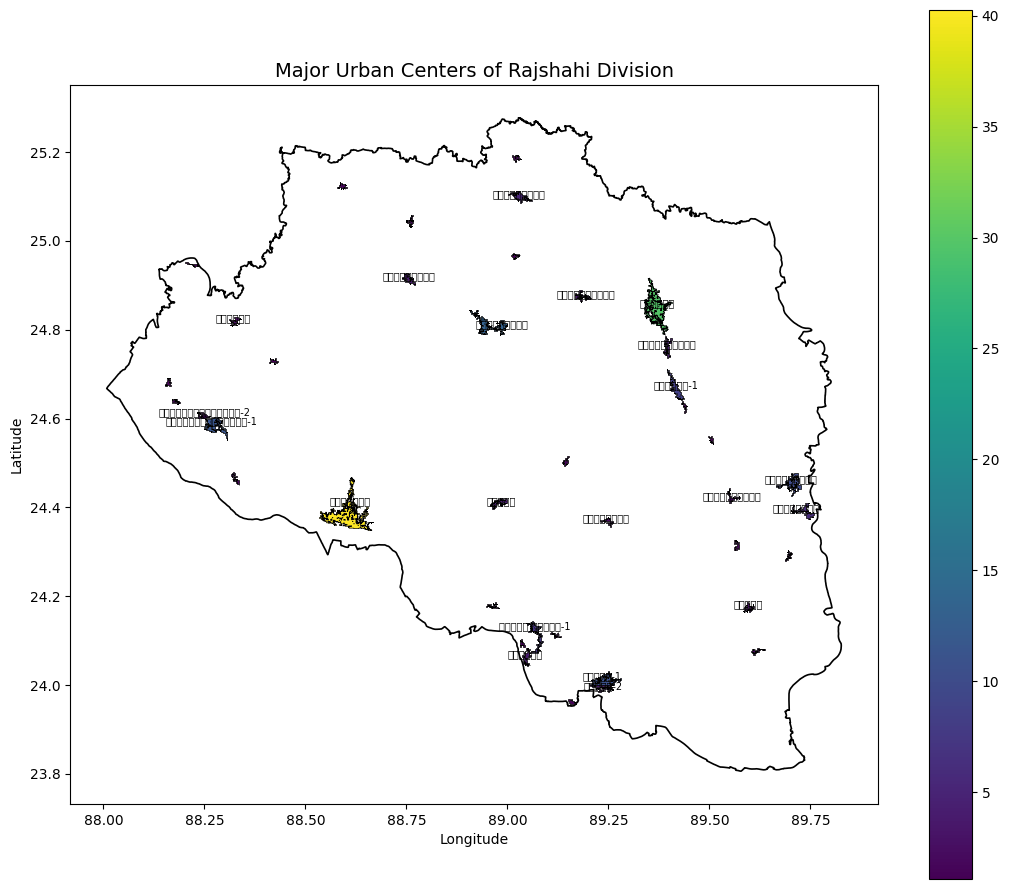


✅ Final map saved.

FINAL RAJSHAHI SUMMARY
Threshold basis     : P92.5
Threshold value     : 0.541772
Minimum patch       : 100 ha
Major urban centers : 40
Total urban area    : 203.07 km²
Largest center      : 40.26 km²
Median center area  : 2.09 km²
Unique names        : 40

FINAL ZIP PACKAGE

ZIP: /content/drive/MyDrive/GEE_Rajshahi_Urban/FINAL_OUTPUTS/Rajshahi_Final_Urban_Center_All_Outputs.zip
ZIP size: 2.59 MB

Included files:
 - Rajshahi_Final_40_Named_Urban_Centers.shp
 - Rajshahi_Final_40_Named_Urban_Centers.shx
 - Rajshahi_Final_40_Named_Urban_Centers.dbf
 - Rajshahi_Final_40_Named_Urban_Centers.cpg
 - Rajshahi_Final_40_Named_Urban_Centers.prj
 - Rajshahi_Final_40_Named_Urban_Centers.gpkg
 - Rajshahi_Final_40_Representative_Points.shp
 - Rajshahi_Final_40_Representative_Points.shx
 - Rajshahi_Final_40_Representative_Points.dbf
 - Rajshahi_Final_40_Representative_Points.cpg
 - Rajshahi_Final_40_Representative_Points.prj
 - Rajshahi_Final_Urban_Score_100m.tif
 - Rajshahi_Final

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [38]:
# ============================================================
# CELL 35 — FINAL RAJSHAHI OUTPUT PACKAGE
#
# Final method:
# Threshold = P92.5
# Minimum patch = 100 ha
#
# Mask:
# 0   = Non-Urban
# 1   = Urban
# 255 = Outside Rajshahi
# ============================================================

import os
import glob
import zipfile
import numpy as np
import geopandas as gpd
import rasterio
import matplotlib.pyplot as plt

from google.colab import files

print("=" * 75)
print("FINAL RAJSHAHI URBAN CENTER OUTPUT PACKAGE")
print("=" * 75)

# ------------------------------------------------------------
# 1. Final output folder
# ------------------------------------------------------------

FINAL_DIR = (
    "/content/drive/MyDrive/"
    "GEE_Rajshahi_Urban/"
    "FINAL_OUTPUTS"
)

os.makedirs(
    FINAL_DIR,
    exist_ok=True
)

print("\nOutput folder:")
print(FINAL_DIR)

# ------------------------------------------------------------
# 2. Merge cleaned names with polygons
# ------------------------------------------------------------

name_table = (
    final_names[
        [
            "center_id",
            "urban_name",
            "district_name"
        ]
    ]
    .copy()
)

final_named = (
    major_centers
    .merge(
        name_table,
        on="center_id",
        how="left"
    )
)

final_named = final_named[
    [
        "center_id",
        "urban_name",
        "district_name",
        "area_ha",
        "area_km2",
        "geometry"
    ]
].copy()

print(
    "\nFinal named centers:",
    len(final_named)
)

print(
    "Missing names:",
    final_named[
        "urban_name"
    ].isna().sum()
)

# ------------------------------------------------------------
# 3. Save final Urban Score TIFF
# ------------------------------------------------------------

SCORE_TIF = os.path.join(
    FINAL_DIR,
    "Rajshahi_Final_Urban_Score_100m.tif"
)

score_profile = {
    "driver": "GTiff",
    "height": height,
    "width": width,
    "count": 1,
    "dtype": "float32",
    "crs": "EPSG:6933",
    "transform": transform_6933,
    "nodata": -9999.0,
    "compress": "lzw"
}

score_out = np.where(
    np.isfinite(
        urban_score_6933
    ),
    urban_score_6933,
    -9999.0
).astype("float32")

with rasterio.open(
    SCORE_TIF,
    "w",
    **score_profile
) as dst:

    dst.write(
        score_out,
        1
    )

    dst.set_band_description(
        1,
        "Urban_Score"
    )

print(
    "\n✅ Final Urban Score TIFF saved."
)

# ------------------------------------------------------------
# 4. Save full Urban / Non-Urban mask
# ------------------------------------------------------------

MASK_TIF = os.path.join(
    FINAL_DIR,
    "Rajshahi_Final_Major_Urban_Center_Mask.tif"
)

final_mask_full = np.full(
    (height, width),
    255,
    dtype="uint8"
)

# Inside Rajshahi = Non-Urban
final_mask_full[
    boundary_mask_6933 == 1
] = 0

# Final major urban centers = Urban
final_mask_full[
    (boundary_mask_6933 == 1)
    & final_major_mask
] = 1

mask_profile = score_profile.copy()

mask_profile.update(
    dtype="uint8",
    nodata=255
)

with rasterio.open(
    MASK_TIF,
    "w",
    **mask_profile
) as dst:

    dst.write(
        final_mask_full,
        1
    )

    dst.set_band_description(
        1,
        "Major_Urban_Center_Mask"
    )

print(
    "✅ Urban / Non-Urban mask saved."
)

# ------------------------------------------------------------
# 5. Mask check
# ------------------------------------------------------------

urban_pixels = int(
    np.sum(
        final_mask_full == 1
    )
)

nonurban_pixels = int(
    np.sum(
        final_mask_full == 0
    )
)

nodata_pixels = int(
    np.sum(
        final_mask_full == 255
    )
)

print("\nMask values:")
print("0   = Non-Urban")
print("1   = Urban")
print("255 = Outside Rajshahi")

print("\nPixel counts:")
print("Non-Urban :", nonurban_pixels)
print("Urban     :", urban_pixels)
print("NoData    :", nodata_pixels)

print(
    "Urban area:",
    round(
        urban_pixels * 0.01,
        2
    ),
    "km²"
)

# ------------------------------------------------------------
# 6. Save Shapefile
# ------------------------------------------------------------

FINAL_SHP = os.path.join(
    FINAL_DIR,
    "Rajshahi_Final_40_Named_Urban_Centers.shp"
)

final_named.to_file(
    FINAL_SHP,
    driver="ESRI Shapefile"
)

print(
    "\n✅ Final named shapefile saved."
)

# ------------------------------------------------------------
# 7. Save GeoPackage
# ------------------------------------------------------------

FINAL_GPKG = os.path.join(
    FINAL_DIR,
    "Rajshahi_Final_40_Named_Urban_Centers.gpkg"
)

final_named.to_file(
    FINAL_GPKG,
    layer="urban_centers",
    driver="GPKG"
)

print(
    "✅ Final GeoPackage saved."
)

# ------------------------------------------------------------
# 8. Representative points
# ------------------------------------------------------------

final_points = (
    final_named
    .copy()
)

final_points["geometry"] = (
    final_points.geometry
    .representative_point()
)

final_points = (
    final_points
    .to_crs("EPSG:4326")
)

final_points["longitude"] = (
    final_points.geometry.x
)

final_points["latitude"] = (
    final_points.geometry.y
)

POINT_SHP = os.path.join(
    FINAL_DIR,
    "Rajshahi_Final_40_Representative_Points.shp"
)

final_points[
    [
        "center_id",
        "urban_name",
        "area_ha",
        "area_km2",
        "longitude",
        "latitude",
        "geometry"
    ]
].to_file(
    POINT_SHP,
    driver="ESRI Shapefile"
)

print(
    "✅ Representative point shapefile saved."
)

# ------------------------------------------------------------
# 9. Save CSV
# ------------------------------------------------------------

CSV_FILE = os.path.join(
    FINAL_DIR,
    "Rajshahi_Final_40_Urban_Centers_Table.csv"
)

final_points.drop(
    columns="geometry"
).to_csv(
    CSV_FILE,
    index=False
)

print(
    "✅ Final CSV table saved."
)

# ------------------------------------------------------------
# 10. Final map
# ------------------------------------------------------------

map_centers = (
    final_named
    .to_crs("EPSG:4326")
)

boundary_map = (
    rajshahi_wgs84
    .copy()
)

fig, ax = plt.subplots(
    figsize=(11, 9)
)

boundary_map.plot(
    ax=ax,
    facecolor="none",
    edgecolor="black",
    linewidth=1.2
)

map_centers.plot(
    ax=ax,
    column="area_km2",
    legend=True,
    edgecolor="black",
    linewidth=0.5
)

# Label centers >= 2 km²
label_centers = map_centers[
    map_centers["area_km2"] >= 2.0
]

for _, row in label_centers.iterrows():

    p = row.geometry.representative_point()

    ax.text(
        p.x,
        p.y,
        str(
            row["urban_name"]
        ),
        fontsize=7,
        ha="center"
    )

ax.set_title(
    "Major Urban Centers of Rajshahi Division",
    fontsize=14
)

ax.set_xlabel(
    "Longitude"
)

ax.set_ylabel(
    "Latitude"
)

plt.tight_layout()

MAP_PNG = os.path.join(
    FINAL_DIR,
    "Rajshahi_Final_Major_Urban_Centers_Map.png"
)

plt.savefig(
    MAP_PNG,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "\n✅ Final map saved."
)

# ------------------------------------------------------------
# 11. Final summary
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("FINAL RAJSHAHI SUMMARY")
print("=" * 75)

print(
    "Threshold basis     : P92.5"
)

print(
    "Threshold value     :",
    round(
        P925,
        6
    )
)

print(
    "Minimum patch       : 100 ha"
)

print(
    "Major urban centers :",
    len(final_named)
)

print(
    "Total urban area    :",
    round(
        final_named[
            "area_km2"
        ].sum(),
        2
    ),
    "km²"
)

print(
    "Largest center      :",
    round(
        final_named[
            "area_km2"
        ].max(),
        2
    ),
    "km²"
)

print(
    "Median center area  :",
    round(
        final_named[
            "area_km2"
        ].median(),
        2
    ),
    "km²"
)

print(
    "Unique names        :",
    final_named[
        "urban_name"
    ].nunique()
)

# ------------------------------------------------------------
# 12. Create ZIP
# ------------------------------------------------------------

files_to_zip = []

for base_name in [
    "Rajshahi_Final_40_Named_Urban_Centers",
    "Rajshahi_Final_40_Representative_Points"
]:

    files_to_zip.extend(
        glob.glob(
            os.path.join(
                FINAL_DIR,
                base_name + ".*"
            )
        )
    )

files_to_zip.extend([
    SCORE_TIF,
    MASK_TIF,
    FINAL_GPKG,
    CSV_FILE,
    MAP_PNG
])

files_to_zip = list(
    dict.fromkeys(
        files_to_zip
    )
)

ZIP_FILE = os.path.join(
    FINAL_DIR,
    "Rajshahi_Final_Urban_Center_All_Outputs.zip"
)

with zipfile.ZipFile(
    ZIP_FILE,
    "w",
    zipfile.ZIP_DEFLATED
) as z:

    for fp in files_to_zip:

        if os.path.isfile(fp):

            z.write(
                fp,
                arcname=os.path.basename(
                    fp
                )
            )

print("\n" + "=" * 75)
print("FINAL ZIP PACKAGE")
print("=" * 75)

print(
    "\nZIP:",
    ZIP_FILE
)

print(
    "ZIP size:",
    round(
        os.path.getsize(
            ZIP_FILE
        )
        / (1024 * 1024),
        2
    ),
    "MB"
)

print("\nIncluded files:")

with zipfile.ZipFile(
    ZIP_FILE,
    "r"
) as z:

    for name in z.namelist():
        print(" -", name)

print(
    "\n✅ ALL FINAL RAJSHAHI OUTPUTS READY."
)

# ------------------------------------------------------------
# 13. Download ZIP
# ------------------------------------------------------------

files.download(
    ZIP_FILE
)